# Jordan 2015-2026: the squad, the opposition, and the goals

Notebook 01 found the shift: Jordan's opponent-adjusted strength rose ~0.7 goals
of expected goal difference between 2015 and 2026, carried by **attack** rather
than defence (+0.744, 95% [+0.238, +1.212]), and no regional peer matched it.

**Who scored the extra goals, and how many players did it take?** If a broad
group, Jordan built a better team. If a handful, Jordan found a few players. The
second is more fragile, and it is the one the data points to.

Window **2015+**, split **2022-07-01** — a date section 0 puts on trial first.
Every difference carries a block-bootstrap interval clustered on six-month
windows (Künsch 1989): matches inside a window share opponents, a manager and a
squad.

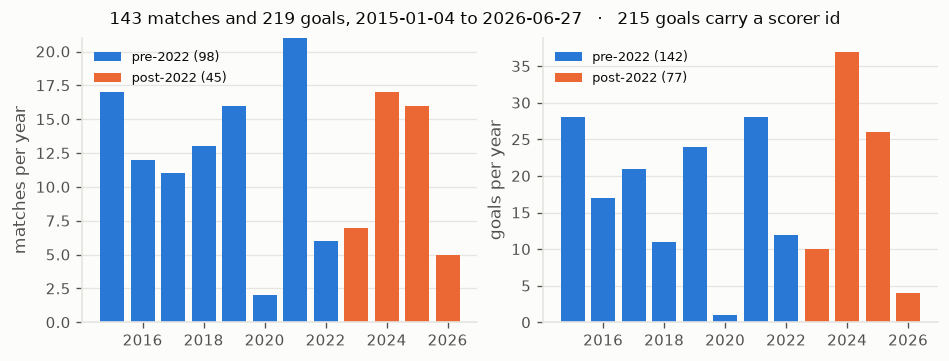

In [1]:
import sys, json
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))
import viz
viz.use_style()

SQUAD = ROOT / "outputs" / "squad"
START, CUT = pd.Timestamp("2015-01-01"), pd.Timestamp(viz.SPLIT)
rng = np.random.default_rng(41)

mt = pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"]).sort_values("date")
goals = pd.read_csv(SQUAD / "goals.csv", parse_dates=["date"])
ap = pd.read_csv(SQUAD / "appearances_combined.csv")
ja = ap[ap.squad_id == "3e22f0fa"].copy()
ja["Min"] = pd.to_numeric(ja.Min, errors="coerce")

mt = mt[mt.date >= START].copy()
goals = goals[goals.date >= START].copy()
for d in (mt, goals):
    d["era"] = np.where(d.date < CUT, "pre", "post")
mt["blk"] = mt.date.dt.year * 2 + (mt.date.dt.month > 6)

# A scorer is a player id, never a name -- the same man is transliterated
# several ways across sources (notebook 02, section 5).
gj = goals.dropna(subset=["scorer_player_id"]).copy()
NAMES = ja.dropna(subset=["player_id"]).groupby("player_id").Player.agg(
    lambda s: s.mode().iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 2.9))
yr = (mt.groupby([mt.date.dt.year, "era"]).size().unstack("era")
      .reindex(columns=["pre", "post"]).fillna(0))
gy = (goals.groupby([goals.date.dt.year, "era"]).size().unstack("era")
      .reindex(columns=["pre", "post"]).fillna(0))
for ax, tab, lab in ((axes[0], yr, "matches"), (axes[1], gy, "goals")):
    ax.bar(tab.index, tab["pre"], width=0.78, color=viz.BLUE,
           label=f"pre-2022 ({int(tab['pre'].sum())})")
    ax.bar(tab.index, tab["post"], bottom=tab["pre"], width=0.78, color=viz.ORANGE,
           label=f"post-2022 ({int(tab['post'].sum())})")
    ax.set_ylabel(f"{lab} per year")
    ax.legend(fontsize=8, loc="upper left")
    viz.despine(ax)
fig.suptitle(f"{len(mt)} matches and {len(goals)} goals, "
             f"{mt.date.min().date()} to {mt.date.max().date()}   ·   "
             f"{len(gj)} goals carry a scorer id", fontsize=10)
plt.show()

## 0. Where the cut comes from

The cut is **not** this notebook's to choose. Notebook 01's opponent-adjusted
strength model is what establishes that the results shifted, and **2022-07-01**
is where that shift sits. What the squad data can add is *what was happening
around it* — so this section puts the two on one timeline.

It is worth saying what this is not. There is no step change in the squad
measures to find, and looking for one was a mistake: what the composition data
shows is an **arc**, and the model's turn sits inside it.

Reading the middle panel: it is the share of Jordan's previous 24 months that
the average starter had already started — 0 if the XI is all new, 1 if the same
eleven started every match for two years. It begins in 2016 because that
lookback needs filling, and each marker's area is the matches behind that year,
so 2020's two fixtures show as a small dot rather than a confident one.

In [2]:
# One function per measure, each over an arbitrary set of matches, so the same
# code can be pointed at any candidate date. Sections 1 and 3 reuse them.
pos_by_match = {m: s.scorer_position.dropna().tolist() for m, s in goals.groupby("match_id")}
mins_by_match = {m: s.groupby("player_id").Min.sum() for m, s in ja.groupby("match_id")}
xi = mt.dropna(subset=["starting_xi"]).copy()
xi["ids"] = xi.starting_xi.map(lambda s: [p["id"] for p in json.loads(s) if p.get("id")])
XI = xi.set_index("match_id")

def mf_share(d):
    v = [p for m in d.match_id for p in pos_by_match.get(m, [])]
    return np.mean([x == "MF" for x in v]) if v else np.nan

def top11(d):
    tot = {}
    for m in d.match_id:
        s = mins_by_match.get(m)
        if s is None:
            continue
        for pid, v in s.items():
            tot[pid] = tot.get(pid, 0) + v
    if not tot:
        return np.nan
    p = pd.Series(tot).sort_values(ascending=False)
    return p.head(11).sum() / p.sum()

def top3_share(d):
    g = gj[gj.match_id.isin(set(d.match_id))].scorer_player_id
    if len(g) < 20:                    # too few goals to form a share
        return np.nan
    return g.value_counts(normalize=True).head(3).sum()

# Familiarity and appearance rate depend on the match and the FULL history
# behind it, never on which matches a bootstrap draw happens to pick -- so they
# are computed once per match here, and resampling only averages them.
# Both are divided by the matches available in the 24-month window, making them
# rates: raw counts accumulate with time and FBref's coverage starts in 2011, so
# the unadjusted versions rise for reasons that have nothing to do with Jordan.
fam_rate, caps_rate = {}, {}
for r in xi.itertuples():
    prior = xi[(xi.date >= r.date - pd.Timedelta(days=730)) & (xi.date < r.date)]
    if len(prior) < 15:                # too little history to form a rate
        continue
    pc, cc = {}, {}
    for q in prior.itertuples():
        for pair in combinations(sorted(q.ids), 2):
            pc[pair] = pc.get(pair, 0) + 1
        for i in q.ids:
            cc[i] = cc.get(i, 0) + 1
    pairs = list(combinations(sorted(r.ids), 2))
    fam_rate[r.match_id] = np.mean([pc.get(p, 0) for p in pairs]) / len(prior)
    caps_rate[r.match_id] = np.mean([cc.get(i, 0) for i in r.ids]) / len(prior)

def windowed(d, which):
    src = fam_rate if which == "fam" else caps_rate
    v = [src[m] for m in d.match_id if m in src]
    return np.mean(v) if v else np.nan

# coverage of these two rates is reported on the section 3 figure
XI_COVER = (len(fam_rate), len(xi))

In [3]:
# The model's own trace, and the squad's history, on one clock.
tr = pd.read_csv(ROOT / "outputs" / "jordan_strength_ci.csv", parse_dates=["date"])
tr = tr[tr.date >= START]

# First-time starters need the FULL table, not the 2015+ window -- a player who
# debuted in 2013 is not a debutant in 2015.
allm = (pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"])
        .sort_values("date").dropna(subset=["starting_xi"]))
allm["ids"] = allm.starting_xi.map(lambda s: [p["id"] for p in json.loads(s) if p.get("id")])
seen, deb = set(), []
for r in allm.itertuples():
    deb.append({"date": r.date, "new": len([i for i in r.ids if i not in seen])})
    seen.update(r.ids)
deb = pd.DataFrame(deb)
deb = deb[deb.date >= START]

# Squad measures per calendar year: half-years get as thin as one match, and a
# rate built on one match is not a point worth plotting.
mt["year"] = mt.date.dt.year
yr = []
for y, d in mt.groupby("year"):
    have = sum(1 for m in d.match_id if m in fam_rate)   # matches with a rate
    yr.append({"year": y, "n": len(d), "n_rate": have,
               "familiarity": windowed(d, "fam"),
               "appearance rate": windowed(d, "caps"),
               "minutes top-11": top11(d)})
yr = pd.DataFrame(yr)
# The rate needs 24 months of prior lineups, so the first year of the window has
# almost none: 2015 qualifies 1 match of 17, at the bare 15-match minimum. That
# is the lookback filling, not a measurement -- the series starts once most of a
# year's matches can carry a rate, and is unbroken from there.
RATE_FROM = int(yr.year[yr.n_rate / yr.n >= 0.5].min())
yrr = yr[yr.year >= RATE_FROM]
yr["debuts"] = deb.groupby(deb.date.dt.year).new.sum().reindex(yr.year).values

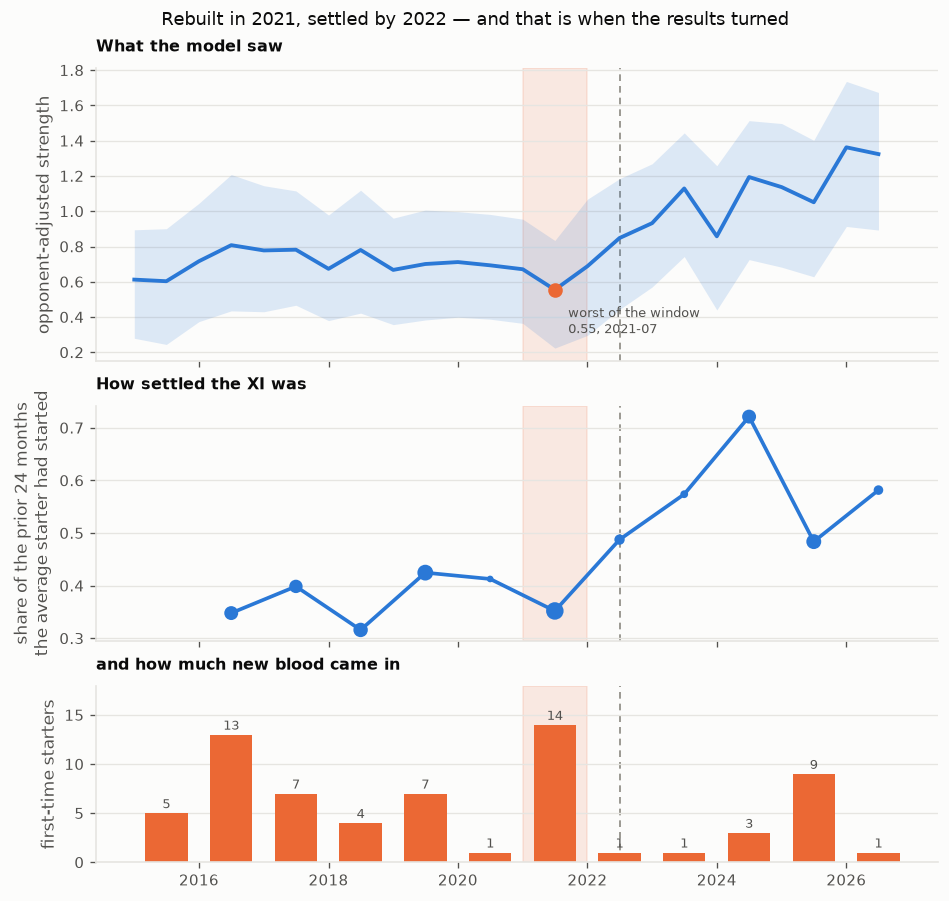

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(7.8, 7.4), sharex=True,
                         gridspec_kw={"height_ratios": [1.5, 1.2, 0.9]})
REBUILD = (pd.Timestamp("2021-01-01"), pd.Timestamp("2022-01-01"))
for ax in axes:
    ax.axvspan(*REBUILD, color=viz.ORANGE, alpha=0.13, zorder=0)
    ax.axvline(CUT, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)

a = axes[0]
a.fill_between(tr.date, tr.strength_lo, tr.strength_hi, color=viz.BLUE,
               alpha=0.15, lw=0)
a.plot(tr.date, tr.strength, color=viz.BLUE, lw=2.3)
trough = tr.loc[tr.strength.idxmin()]
a.scatter([trough.date], [trough.strength], color=viz.ORANGE, s=60, zorder=4)
a.annotate(f"worst of the window\n{trough.strength:.2f}, {str(trough.date.date())[:7]}",
           xy=(trough.date, trough.strength), xytext=(8, -26),
           textcoords="offset points", fontsize=8, color=viz.INK_2)
a.set_ylabel("opponent-adjusted strength")
a.set_title("What the model saw", fontsize=9.5)
viz.despine(a)

b = axes[1]
mid = pd.to_datetime(yr.year.astype(str) + "-07-01")
midr = pd.to_datetime(yrr.year.astype(str) + "-07-01")
# Appearance rate rather than familiarity: the two track each other at r = 0.99,
# and this is the one that reads without a paragraph of setup. Section 3 reports
# both.
b.plot(midr, yrr["appearance rate"], color=viz.BLUE, lw=2.2)
b.scatter(midr, yrr["appearance rate"], color=viz.BLUE, s=yrr.n_rate * 4.5,
          zorder=3)
b.set_ylabel("share of the prior 24 months\nthe average starter had started")
b.set_title("How settled the XI was", fontsize=9.5)
viz.despine(b)

c = axes[2]
c.bar(mid, yr.debuts, width=240, color=viz.ORANGE)
for x_, v in zip(mid, yr.debuts):
    if v:
        c.annotate(int(v), (x_, v), xytext=(0, 3), ha="center",
                   textcoords="offset points", fontsize=8, color=viz.INK_2)
c.set_ylabel("first-time starters")
c.set_ylim(0, yr.debuts.max() * 1.28)
c.set_title("and how much new blood came in", fontsize=9.5)
viz.despine(c)
c.grid(axis="x", visible=False)

fig.suptitle("Rebuilt in 2021, settled by 2022 — and that is when the results turned",
             fontsize=11)
plt.show()

**An arc, not a step.** Jordan rebuilt through 2021 — **14 first-time starters
in 21 matches** — and it cost them: the model's **lowest strength of the entire
window, 0.555 in July 2021**, below anything in 2015-19. Then the squad closed:
**two** first-time starters in the next two and a half years, familiarity
roughly doubling as the same eleven accumulated time together, and strength
climbing from 0.69 to a peak above 1.1.

The cut sits just after the turn in both series. It is not a wall between two
regimes — it is the point where a squad assembled in 2021 started playing
together.

🚨 **The link is not tight, and the timeline should not be read as though it
were.** 2026H1 is the **highest strength in the window** with familiarity
already fallen back, and 2025 reopened the squad — nine first-time starters —
without the results collapsing. Composition and strength move together over this
one cycle. That is a coincidence with uncertainty, which is all this design can
carry, and the same caution the summary closes on.

Read the second figure top to bottom and the arc is in the raw data: a staircase
of new rows through 2021, then long unbroken runs across the middle as the same
names start match after match, then a second staircase from 2025.

On the cut date itself, checked rather than shown: recomputing every pre/post
difference at all 14 cuts with 25 matches a side (2017-01 to 2024-07), the
settledness and midfield measures keep their sign wherever the line falls. The
two concentration measures go negative only at the earliest cuts, where "pre" is
29 matches of 2015-16 — a different team, not a fragile finding.

## 1. The squad

Section 0 showed *when* things changed. This asks *what* changed, in the only
material this notebook has direct access to: who was picked, in what shape, and
how often that changed.

Four questions:

1. **What formation did Jordan play, and when did that move?**
2. **Did the shape settle, or just the personnel?**
3. **How concentrated did the playing time become?**
4. **How much did the XI change from one match to the next?**

In [5]:
# Formation comes two ways and they can be checked against each other: FBref's
# reported label, and the shape derived from the positions in the XI. Where both
# exist they agree on the size of the back line in every single match, so
# formation_best (label, falling back to derived) is safe to use across eras.
mt["backline"] = pd.to_numeric(mt.formation_best.astype(str).str.split("-").str[0],
                               errors="coerce")
mt["line"] = np.where(mt.backline.isin([3, 5]), "back 3 or 5",
                       np.where(mt.backline == 4, "back 4", None))
both = mt.dropna(subset=["formation", "xi_shape"])
AGREE = (both.formation.str.split("-").str[0]
         == both.xi_shape.str.split("-").str[0]).mean()
FORM_N = (len(both), int(mt.line.notna().sum()), len(mt))
# six-month blocks, needed here and reused by the settledness cell below
BLOCKS_F = {e: [d for _, d in mt[mt.era == e].groupby("blk")]
            for e in ("pre", "post")}

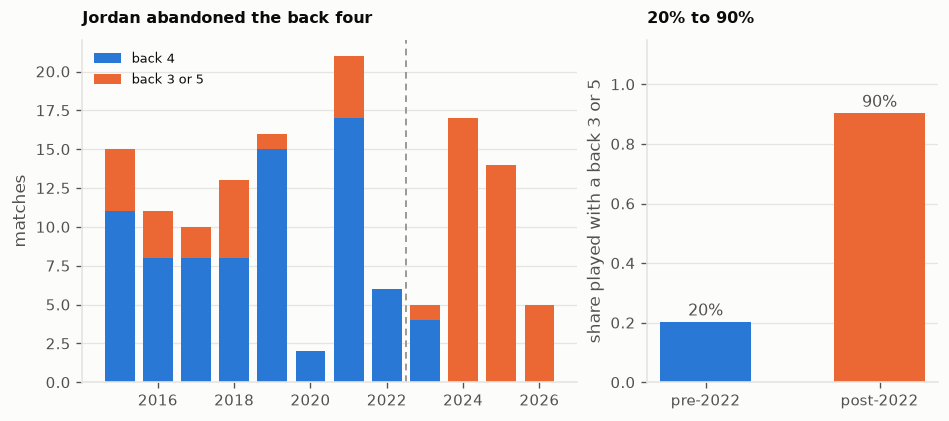

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.4),
                         gridspec_kw={"width_ratios": [1.7, 1]})
a = axes[0]
d = mt.dropna(subset=["line"])
t = pd.crosstab(d.date.dt.year, d.line)
for c in ("back 4", "back 3 or 5"):
    if c not in t:
        t[c] = 0
t = t[["back 4", "back 3 or 5"]]
a.bar(t.index, t["back 4"], color=viz.BLUE, label="back 4", width=0.78)
a.bar(t.index, t["back 3 or 5"], bottom=t["back 4"], color=viz.ORANGE,
      label="back 3 or 5", width=0.78)
a.axvline(CUT.year + 0.5, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
a.set_ylabel("matches")
a.set_title("Jordan abandoned the back four", fontsize=9.5)
a.legend(fontsize=8, loc="upper left")
viz.despine(a)

b = axes[1]
sh = (d.assign(b3=d.line.eq("back 3 or 5"))
      .groupby("era").b3.mean().reindex(["pre", "post"]))
b.bar([0, 1], sh.values, width=0.52, color=[viz.BLUE, viz.ORANGE])
for i, v in enumerate(sh.values):
    b.annotate(f"{v:.0%}", (i, v), xytext=(0, 4), ha="center",
               textcoords="offset points", fontsize=9.5, color=viz.INK_2)
b.set_xticks([0, 1])
b.set_xticklabels(["pre-2022", "post-2022"])
b.set_ylim(0, 1.15)
b.set_ylabel("share played with a back 3 or 5")
b.set_title("20% to 90%", fontsize=9.5)
viz.despine(b)
plt.show()

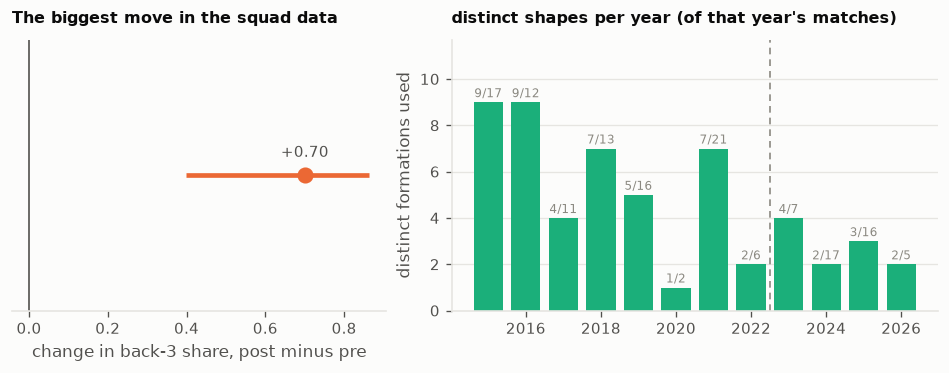

In [7]:
# Did the SHAPE settle, or only the personnel? Count distinct formations used in
# each year, and bootstrap the era difference in the back-3 share.
# A match with no recorded formation is NOT evidence of a back four, so the
# unknowns leave the denominator rather than counting against it. Eight matches,
# four each era; including them understates the change by 0.07.
def b3(frame):
    v = frame.line.dropna()
    return v.eq("back 3 or 5").mean() if len(v) else np.nan

obs = b3(mt[mt.era == "post"]) - b3(mt[mt.era == "pre"])
dr = []
for _ in range(3000):
    v = []
    for e in ("pre", "post"):
        pick = pd.concat([BLOCKS_F[e][i]
                          for i in rng.integers(0, len(BLOCKS_F[e]), len(BLOCKS_F[e]))])
        v.append(b3(pick))
    if np.isfinite(v[0]) and np.isfinite(v[1]):
        dr.append(v[1] - v[0])
BACK3 = (obs, *np.percentile(dr, [2.5, 97.5]))

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0),
                         gridspec_kw={"width_ratios": [1, 1.3]})
a = axes[0]
a.hlines(0, BACK3[1], BACK3[2], color=viz.ORANGE, lw=2.8)
a.scatter([BACK3[0]], [0], color=viz.ORANGE, s=75, zorder=3)
a.axvline(0, color=viz.INK_2, lw=1.0)
a.annotate(f"{BACK3[0]:+.2f}", (BACK3[0], 0), xytext=(0, 11), ha="center",
           textcoords="offset points", fontsize=9, color=viz.INK_2)
a.set_ylim(-1, 1)
a.set_yticks([])
a.set_xlabel("change in back-3 share, post minus pre")
a.set_title("The biggest move in the squad data", fontsize=9.5)
viz.despine(a, keep=("bottom",))

b = axes[1]
nf = mt.dropna(subset=["formation_best"]).groupby(mt.date.dt.year).formation_best.nunique()
nm = mt.groupby(mt.date.dt.year).size()
b.bar(nf.index, nf.values, color=viz.AQUA, width=0.78)
for x_, v, m_ in zip(nf.index, nf.values, nm.reindex(nf.index).values):
    b.annotate(f"{v}/{m_}", (x_, v), xytext=(0, 3), ha="center",
               textcoords="offset points", fontsize=7, color=viz.INK_MUTED)
b.axvline(CUT.year + 0.5, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
b.set_ylabel("distinct formations used")
b.set_ylim(0, nf.max() * 1.3)
b.set_title("distinct shapes per year (of that year's matches)", fontsize=9.5)
viz.despine(b)
plt.show()

**Jordan stopped being a back-four team.** A back three or five appears in
**20%** of pre-2022 matches and **90%** after — a change of **+0.71, 95%
[+0.43, +0.87]**, and the largest single move anywhere in the squad data.

This is not a labelling artefact. FBref's reported formation and the shape
derived independently from the XI's own positions agree on the size of the back
line in **every match where both exist**, and each source on its own gives the
same story (0.10 → 0.89 reported, 0.20 → 0.90 derived).

It matters beyond itself, because a fixed shape makes a fixed eleven much easier
to pick — and because it puts more midfielders on the pitch, which is going to
turn up again in section 3.

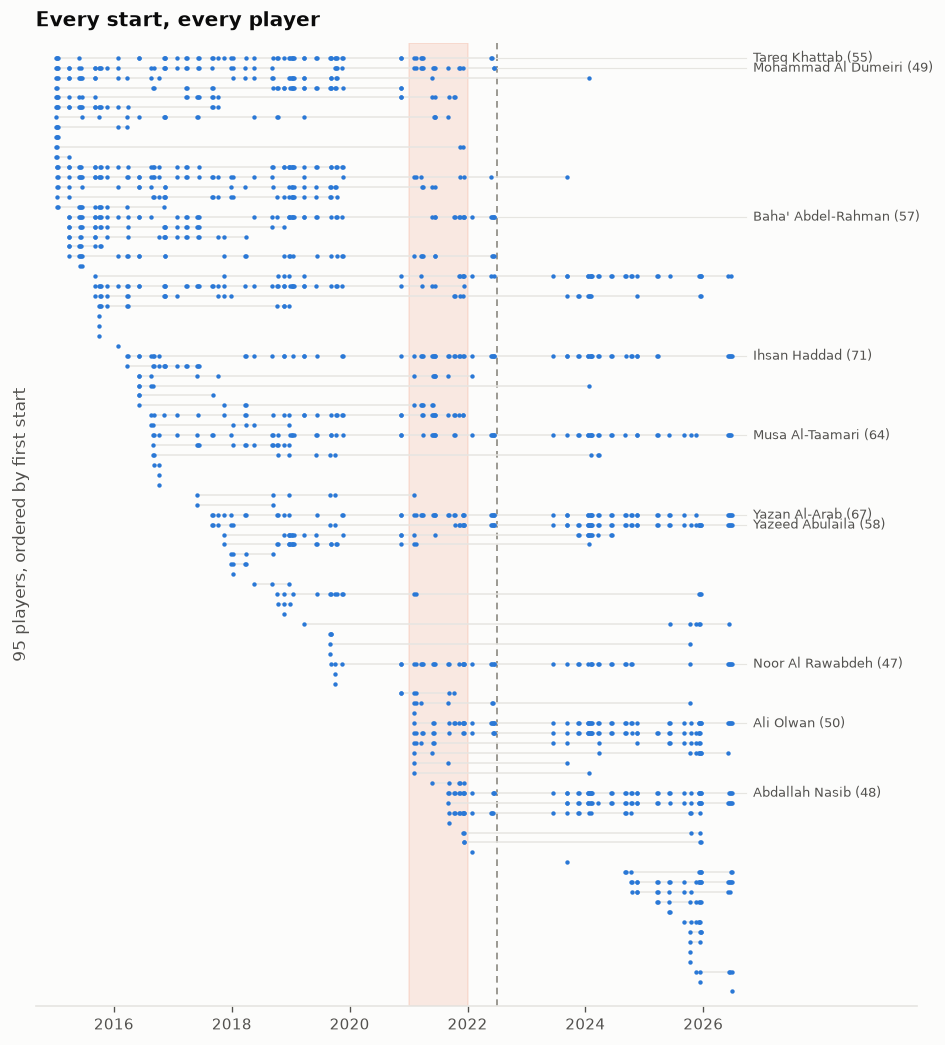

In [8]:
# Every measure in this notebook reduces to one fact: who started which match.
# Draw that fact. Players ordered by first start, so a rebuild reads as a
# staircase of new rows and a settled side as long runs across the top.
starts = {}
for r in xi[xi.date >= START].sort_values("date").itertuples():
    for pid in r.ids:
        starts.setdefault(pid, []).append(r.date)
order = sorted(starts, key=lambda p: (starts[p][0], -len(starts[p])))

fig, ax = plt.subplots(figsize=(7.8, 8.6))
ax.axvspan(*REBUILD, color=viz.ORANGE, alpha=0.13, zorder=0)
ax.axvline(CUT, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=1)
for i, pid in enumerate(order):
    d = starts[pid]
    ax.plot([d[0], d[-1]], [i, i], color=viz.GRID, lw=0.9, zorder=2)
    ax.scatter(d, np.full(len(d), i), s=7, color=viz.BLUE, zorder=3,
               linewidths=0)
# name the ten who started most, so the dense rows are identifiable
# Labels in an aligned column on the right, not floating at each career end.
LBL = xi.date.max() + pd.Timedelta(days=90)
for pid in sorted(starts, key=lambda p: -len(starts[p]))[:10]:
    i = order.index(pid)
    ax.plot([starts[pid][-1], LBL], [i, i], color=viz.GRID, lw=0.7, zorder=1)
    ax.annotate(f"{NAMES.get(pid, pid)} ({len(starts[pid])})", xy=(LBL, i),
                xytext=(4, 0), va="center", textcoords="offset points",
                fontsize=7.5, color=viz.INK_2)
ax.set_ylim(-1.5, len(order) + 0.5)
ax.invert_yaxis()
ax.set_yticks([])
ax.set_ylabel(f"{len(order)} players, ordered by first start")
ax.set_xlim(START - pd.Timedelta(days=120),
            xi.date.max() + pd.Timedelta(days=1150))
# ticks stop where the data does, so the right-hand strip reads as a label
# column rather than as two more years of empty fixtures
YRS = list(range(2016, 2027, 2))
ax.set_xticks(pd.to_datetime([f"{y}-01-01" for y in YRS]))
ax.set_xticklabels([str(y) for y in YRS])
ax.set_title("Every start, every player")
viz.despine(ax, keep=("bottom",))
ax.grid(axis="y", visible=False)
plt.show()

Read top to bottom: a staircase of new rows through 2021, long unbroken runs
across the middle as the same names start match after match, and a second
staircase from 2025. That is the raw material every measure in this notebook is
built from.

In [9]:
BLOCKS = {e: [d for _, d in mt[mt.era == e].groupby("blk")] for e in ("pre", "post")}

def block_boot(fn, nb=600):
    """Resample six-month blocks within each era; matches in a window are not
    independent draws, so the block is the unit (Kunsch 1989)."""
    obs = fn(mt[mt.era == "post"]) - fn(mt[mt.era == "pre"])
    vals = []
    for _ in range(nb):
        s = {e: pd.concat([BLOCKS[e][i]
                           for i in rng.integers(0, len(BLOCKS[e]), len(BLOCKS[e]))])
             for e in ("pre", "post")}
        v = fn(s["post"]) - fn(s["pre"])
        if np.isfinite(v):
            vals.append(v)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return obs, lo, hi

# Two measures, not four. Appearance rate is familiarity at player level
# (r = 0.99, and it cannot be exceeded by construction), and midfielder share of
# goals belongs to section 3, where it is tested against the outfield slots
# rather than just stated.
MEASURES = [
    ("minutes: top-11 share", top11, 600),
    ("familiarity rate (pairs)", lambda d: windowed(d, "fam"), 600),
]
res = []
for lab, fn, nb in MEASURES:
    o, lo, hi = block_boot(fn, nb)
    res.append({"measure": lab, "pre": fn(mt[mt.era == "pre"]),
                "post": fn(mt[mt.era == "post"]),
                "diff": o, "lo": lo, "hi": hi,
                "excludes_0": bool(lo > 0 or hi < 0)})
settled = pd.DataFrame(res)   # drawn by the next cell

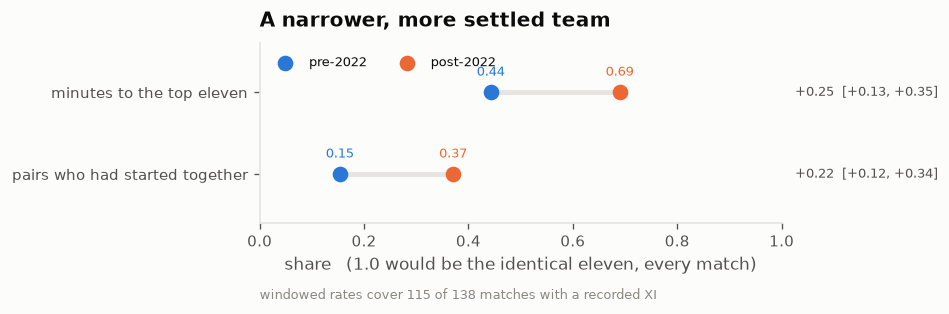

In [10]:
# Levels, not just the change. Both measures are shares on the same scale and
# both mean the same thing at 1.0 -- the identical eleven, every match -- so one
# axis carries them, and the interval rides along as text rather than as the
# whole chart.
fig, ax = plt.subplots(figsize=(7.8, 2.4))
d = settled.iloc[::-1].reset_index(drop=True)
y = np.arange(len(d))
ax.hlines(y, d.pre, d.post, color=viz.GRID, lw=3.0, zorder=1,
          capstyle="round")
ax.scatter(d.pre, y, color=viz.BLUE, s=70, zorder=3, label="pre-2022")
ax.scatter(d.post, y, color=viz.ORANGE, s=70, zorder=3, label="post-2022")
for i, r in d.iterrows():
    ax.annotate(f"{r.pre:.2f}", (r.pre, i), xytext=(0, 10), ha="center",
                textcoords="offset points", fontsize=8, color=viz.BLUE)
    ax.annotate(f"{r.post:.2f}", (r.post, i), xytext=(0, 10), ha="center",
                textcoords="offset points", fontsize=8, color=viz.ORANGE)
    ax.annotate(f"{r['diff']:+.2f}  [{r.lo:+.2f}, {r.hi:+.2f}]",
                (1.0, i), xytext=(8, 0), va="center",
                textcoords="offset points", fontsize=8, color=viz.INK_2)
ax.set_yticks(y)
# labels must follow the (reversed) frame, not a hardcoded list -- getting this
# wrong silently puts the minutes number on the familiarity row
NICE = {"minutes: top-11 share": "minutes to the top eleven",
        "familiarity rate (pairs)": "pairs who had started together"}
ax.set_yticklabels([NICE.get(m, m) for m in d.measure])
ax.set_xlim(0, 1.0)
ax.set_ylim(-0.6, len(d) - 0.4)
ax.set_xlabel("share   (1.0 would be the identical eleven, every match)")
ax.set_title("A narrower, more settled team")
ax.legend(fontsize=8, loc="upper left", ncol=2)
ax.annotate(f"windowed rates cover {XI_COVER[0]} of {XI_COVER[1]} matches "
            f"with a recorded XI", xy=(0, -0.42), xycoords="axes fraction",
            fontsize=7.5, color=viz.INK_MUTED)
viz.despine(ax)
ax.grid(axis="y", visible=False)
plt.show()

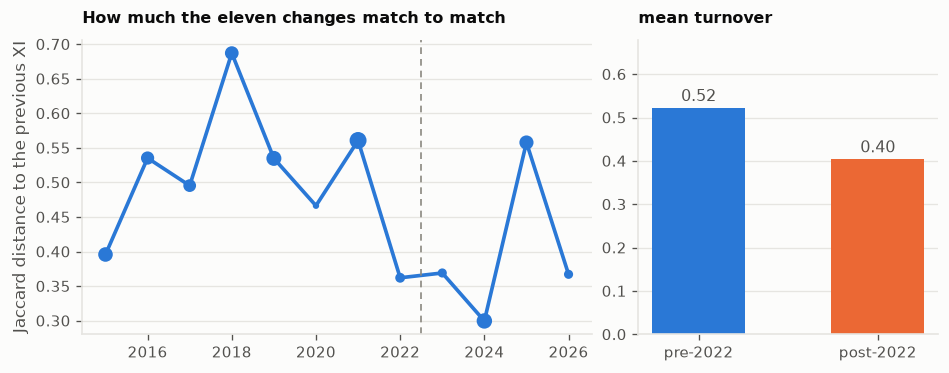

In [11]:
# How much does the XI change from one match to the next? Jaccard distance
# between consecutive starting elevens: 0 = identical side, 1 = eleven changes.
xs = xi.sort_values("date")
jac, jd = [], []
prev = None
for r in xs.itertuples():
    if prev is not None:
        a_, b_ = set(prev), set(r.ids)
        jac.append(1 - len(a_ & b_) / len(a_ | b_))
        jd.append(r.date)
    prev = r.ids
turn = pd.DataFrame({"date": jd, "turnover": jac})
turn["era"] = np.where(turn.date < CUT, "pre", "post")

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0),
                         gridspec_kw={"width_ratios": [1.7, 1]})
a = axes[0]
yr = turn.groupby(turn.date.dt.year).turnover.agg(["mean", "size"])
a.plot(yr.index, yr["mean"], color=viz.BLUE, lw=2.2)
a.scatter(yr.index, yr["mean"], color=viz.BLUE, s=yr["size"] * 4, zorder=3)
a.axvline(CUT.year + 0.5, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
a.set_ylabel("Jaccard distance to the previous XI")
a.set_title("How much the eleven changes match to match", fontsize=9.5)
viz.despine(a)

b = axes[1]
m = turn.groupby("era").turnover.mean().reindex(["pre", "post"])
b.bar([0, 1], m.values, width=0.52, color=[viz.BLUE, viz.ORANGE])
for i, v in enumerate(m.values):
    b.annotate(f"{v:.2f}", (i, v), xytext=(0, 4), ha="center",
               textcoords="offset points", fontsize=9.5, color=viz.INK_2)
b.set_xticks([0, 1])
b.set_xticklabels(["pre-2022", "post-2022"])
b.set_ylim(0, m.max() * 1.3)
b.set_title("mean turnover", fontsize=9.5)
viz.despine(b)
plt.show()

**Both clear zero.** The top eleven take **44% to 69%** of all playing time, and
the average pair in the XI has started **0.15 to 0.37** of the previous two years
together.

Turnover says the same thing from the other side — the eleven that starts is
closer to the eleven that started last time. Note it does **not** fall to zero:
Jordan still changes players, it just changes fewer of them, inside a shape that
no longer changes at all.

### Where they play their club football

The squad narrowed and settled. A different question about the same men: **where
do they earn their living, and did that move?**

FBref cannot answer it — its reader covers nine leagues, none of them Jordanian,
Gulf or Asian. This comes from five Wikipedia tournament squad lists, each row
carrying the club and the club's country at the moment the squad was named.

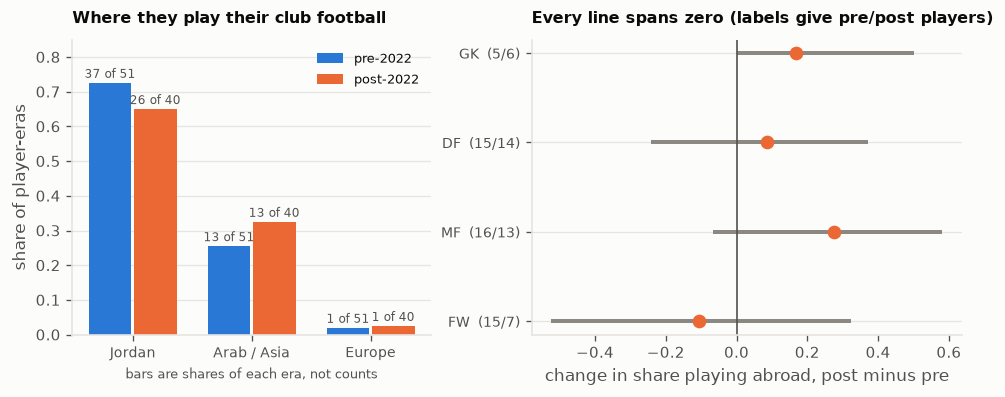

In [12]:
# Where the players earn their club football. FBref cannot answer this -- its
# soccerdata reader covers nine leagues and none of the ones Jordan's players
# are in -- so this comes from Wikipedia tournament squad lists via
# JordanData/wiki_squads.py: five squads, each row carrying the club and the
# club's country at the moment that squad was named.
#
# Counted per PLAYER per era, not per squad place: a regular named in three
# squads would otherwise count three times, and that alone flips the forward
# result from 47%->29% to 56%->56%.
pe = pd.read_csv(SQUAD / "tournament_player_eras.csv")
pe["abroad"] = pe.region.ne("Jordan")
REG = ["Jordan", "Arab / Asia", "Europe"]

fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.2),
                         gridspec_kw={"width_ratios": [1, 1.2]})
a = axes[0]
rs = (pd.crosstab(pe.region, pe.era, normalize="columns")
      .reindex(columns=["pre", "post"]).reindex(REG).fillna(0))
rn = (pd.crosstab(pe.region, pe.era).reindex(columns=["pre", "post"])
      .reindex(REG).fillna(0))
x = np.arange(len(REG))
for off, e, col in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    a.bar(x + off, rs[e], width=0.36, color=col, label=f"{e}-2022")
    # label the DENOMINATOR too: the bars are shares, the eras hold 51 and 40
    # player-eras, so the same count of 13 is a different height in each
    tot_e = int(rn[e].sum())
    for xi_, v, n_ in zip(x + off, rs[e], rn[e]):
        a.annotate(f"{int(n_)} of {tot_e}", (xi_, v), xytext=(0, 3), ha="center",
                   textcoords="offset points", fontsize=7, color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(REG, fontsize=8.5)
a.set_ylim(0, 0.85)
a.set_ylabel("share of player-eras")
a.set_title("Where they play their club football", fontsize=9.5)
a.set_xlabel("bars are shares of each era, not counts", fontsize=7.5)
a.legend(fontsize=8)
viz.despine(a)

b = axes[1]
LINES = ["GK", "DF", "MF", "FW"]
rows = []
for ln in LINES:
    m = pe.pos.eq(ln)
    pa, po = pe[m & pe.era.eq("pre")].abroad, pe[m & pe.era.eq("post")].abroad
    d = [rng.choice(po.values, len(po)).mean() - rng.choice(pa.values, len(pa)).mean()
         for _ in range(4000)]
    lo, hi = np.percentile(d, [2.5, 97.5])
    rows.append({"line": ln, "diff": po.mean() - pa.mean(), "lo": lo, "hi": hi,
                 "n_pre": len(pa), "n_post": len(po)})
ab = pd.DataFrame(rows).iloc[::-1].reset_index(drop=True)
y = np.arange(len(ab))
b.hlines(y, ab.lo, ab.hi, color=viz.INK_MUTED, lw=2.4)
b.scatter(ab["diff"], y, color=viz.ORANGE, s=52, zorder=3)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.set_yticks(y)
b.set_yticklabels([f"{r.line}  ({r.n_pre}/{r.n_post})" for r in ab.itertuples()],
                  fontsize=8.5)
b.set_xlabel("change in share playing abroad, post minus pre")
b.set_title("Every line spans zero (labels give pre/post players)", fontsize=9.5)
viz.despine(b)
plt.show()

🚨 **A measured null, and a thin one.** The share of Jordan's squad playing club
football abroad goes **27.5% to 35.0%** — a difference of **+0.075, 95% [−0.12,
+0.27]**. Every line spans zero too, on between five and sixteen players a cell.
Midfield is the suggestive one (**+0.27, [−0.07, +0.62]**) and fits the rest of
the midfield story, but it cannot be called.

Two things *are* visible. The first is a move into the **Iraqi league** — one
player-era before 2022, seven after, mostly Al-Shorta — while the Bahraini (4 to
0) and Kuwaiti (3 to 0) clubs emptied out entirely.

🚨 **The second is the striking one: Europe has been exactly one player, and the
same player.** Musa Al-Taamari, at APOEL before and Montpellier after. Across
five squads spanning eleven years Jordan has never had a second European-based
man in a tournament squad.

That reframes everything above it. **Jordan reached an Asian Cup final and a
World Cup with a squad roughly two-thirds home-based and one European
professional.** Whatever the settled XI and the back three are worth, they were
worth it without the route most improving nations take. Nothing here can say
what sending players to stronger leagues would do — that is an untested avenue,
not a measured one — but it is the obvious thing this team has not tried, and
the one player who did take it is the same man whose scoring rate doubled.

Caveats the figure cannot carry: this is **five tournament squads, not a career
average**. Friendly call-ups are invisible, and a transfer between tournaments
cannot be seen.

## 2. The opposition

Before asking what Jordan did better, ask who it was playing. The model in
section 0 adjusts for this, but the adjustment hides something a reader needs to
see directly: **the fixture list changed as much as the squad did.**

Six questions:

1. **When did the opponents get harder** — and was it gradual or sudden?
2. **Was that chosen or earned?** Friendlies are picked; qualifiers are not.
3. **Given the opponent, how much better is Jordan?**
4. **Does that gain depend on who it plays** — bigger against weak sides, or the
   same everywhere?
5. **Does venue matter**, now that half the fixtures are on neutral ground?
6. **How does the opposition set up** against Jordan, and did that change?

In [13]:
mt["points"] = mt.result.map({"W": 3, "D": 1, "L": 0})
mt["kind"] = np.where(mt.tournament == "Friendly", "friendly", "competitive")
# expected_gd is Jordan minus opponent: NEGATIVE is the harder fixture.
mt["opp_bl"] = pd.to_numeric(mt.opp_formation.astype(str).str.split("-").str[0],
                             errors="coerce")
mt["opp_line"] = np.where(mt.opp_bl.isin([3, 5]), "back 3 or 5",
                          np.where(mt.opp_bl == 4, "back 4", None))
# expected_gd is a DIFFERENCE: Jordan's strength minus the opponent's, plus the
# model's home-advantage term. Back the opponent out of it, so the two sides can
# be drawn separately. strength_at_match is Jordan's own parameter -- the same
# quantity notebook 01 traces.
_adv = tr.set_index("date").home_adv.sort_index()
mt["adv"] = mt.date.map(lambda d: _adv.reindex(_adv.index.union([d]))
                        .sort_index().ffill().get(d, np.nan))
mt["venue_eff"] = np.where(mt.venue == "home", mt.adv,
                           np.where(mt.venue == "away", -mt.adv, 0.0))
mt["opp_str"] = mt.strength_at_match - (mt.expected_gd - mt.venue_eff)


def _comp_cat(t):
    # the calendar has three modes and they face very different opposition
    if "qualification" in str(t):
        return "qualifying"
    if str(t).startswith("Friendl"):
        return "friendly"
    return "finals"


mt["comp_cat"] = mt.tournament.map(_comp_cat)

BLK = {e: [d for _, d in mt[mt.era == e].groupby("blk")] for e in ("pre", "post")}


def blk_boot(fn, n=3000):
    # resample six-month blocks within each era; returns the observed
    # difference and its 95% interval
    obs = fn(mt[mt.era == "post"]) - fn(mt[mt.era == "pre"])
    v = []
    for _ in range(n):
        s_ = {e: pd.concat([BLK[e][i]
                            for i in rng.integers(0, len(BLK[e]), len(BLK[e]))])
              for e in ("pre", "post")}
        d = fn(s_["post"]) - fn(s_["pre"])
        if np.isfinite(d):
            v.append(d)
    return obs, *np.percentile(v, [2.5, 97.5])

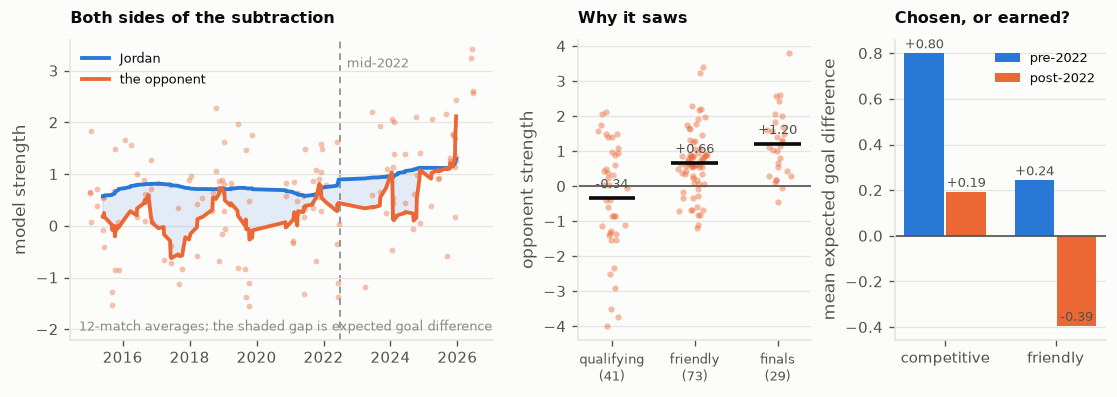

In [14]:
# When did it harden, and was it chosen? Friendlies are arranged; qualifiers are
# drawn. If only the competitive fixtures got harder, that is a consequence of
# going further. If the friendlies hardened too, somebody chose it.
fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.2),
                         gridspec_kw={"width_ratios": [1.9, 1.05, 0.95]})
a = axes[0]
srt = mt.sort_values("date")
jr = srt.set_index("date").strength_at_match.rolling(12, center=True).mean()
orr = srt.set_index("date").opp_str.rolling(12, center=True).mean()
a.fill_between(jr.index, jr.values, orr.values, where=jr.values >= orr.values,
               color=viz.BLUE, alpha=0.12, interpolate=True)
a.fill_between(jr.index, jr.values, orr.values, where=jr.values < orr.values,
               color=viz.ORANGE, alpha=0.14, interpolate=True)
a.scatter(srt.date, srt.opp_str, s=12, color=viz.ORANGE, alpha=0.4, linewidths=0)
a.plot(jr.index, jr.values, color=viz.BLUE, lw=2.3, label="Jordan")
a.plot(orr.index, orr.values, color=viz.ORANGE, lw=2.3, label="the opponent")
viz.mark_split(a)
a.set_ylabel("model strength")
a.set_title("Both sides of the subtraction", fontsize=9.5)
a.annotate("12-match averages; the shaded gap is expected goal difference",
           xy=(0.02, 0.03), xycoords="axes fraction", fontsize=7.5,
           color=viz.INK_MUTED)
# the individual opponents run to +-4 and squash the lines that carry the point
a.set_ylim(-2.2, 3.6)
a.legend(fontsize=8, loc="upper left")
viz.despine(a)

# why the orange line saws: the calendar alternates between qualifying groups
# full of minnows and tournaments full of real teams
b = axes[1]
CATS = ["qualifying", "friendly", "finals"]
for i, c_ in enumerate(CATS):
    d = mt[mt.comp_cat == c_]
    jit = rng.normal(0, 0.07, len(d))
    b.scatter(np.full(len(d), i) + jit, d.opp_str, s=14, alpha=0.45,
              color=viz.ORANGE, linewidths=0)
    b.hlines(d.opp_str.mean(), i - 0.28, i + 0.28, color=viz.INK, lw=2.2)
    b.annotate(f"{d.opp_str.mean():+.2f}", (i, d.opp_str.mean()), xytext=(0, 6),
               ha="center", textcoords="offset points", fontsize=8,
               color=viz.INK_2)
b.axhline(0, color=viz.INK_2, lw=1.0)
b.set_xticks(range(len(CATS)))
b.set_xticklabels([f"{c_}\n({int((mt.comp_cat == c_).sum())})" for c_ in CATS],
                  fontsize=8)
b.set_ylabel("opponent strength")
b.set_title("Why it saws", fontsize=9.5)
viz.despine(b)
b.grid(axis="x", visible=False)

c = axes[2]
x = np.arange(2)
for off, e, col in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    v = [mt[(mt.era == e) & (mt.kind == k)].expected_gd.mean()
         for k in ("competitive", "friendly")]
    c.bar(x + off, v, width=0.36, color=col, label=f"{e}-2022")
    for xi_, vv in zip(x + off, v):
        c.annotate(f"{vv:+.2f}", (xi_, vv), xytext=(0, 3), ha="center",
                   textcoords="offset points", fontsize=8, color=viz.INK_2)
c.axhline(0, color=viz.INK_2, lw=1.0)
c.set_xticks(x)
c.set_xticklabels(["competitive", "friendly"])
c.set_ylabel("mean expected goal difference")
c.set_title("Chosen, or earned?", fontsize=9.5)
c.legend(fontsize=7.5)
viz.despine(c)
plt.show()

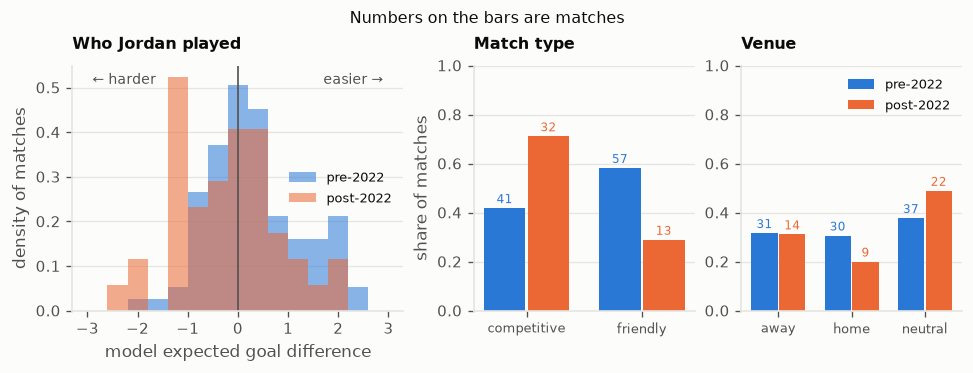

In [15]:
# The fixture list itself: who, what kind, and where.
fig, axes = plt.subplots(1, 3, figsize=(8.0, 3.0),
                         gridspec_kw={"width_ratios": [1.5, 1, 1]})
a = axes[0]
for e, col in (("pre", viz.BLUE), ("post", viz.ORANGE)):
    a.hist(mt[mt.era == e].expected_gd, bins=np.arange(-3, 3.01, 0.4),
           density=True, color=col, alpha=0.55, label=f"{e}-2022")
a.axvline(0, color=viz.INK_2, lw=1.0)
a.annotate("← harder", xy=(-2.9, 0.97), xycoords=("data", "axes fraction"),
           fontsize=8.5, color=viz.INK_2, va="top", ha="left")
a.annotate("easier →", xy=(2.9, 0.97), xycoords=("data", "axes fraction"),
           fontsize=8.5, color=viz.INK_2, va="top", ha="right")
a.set_xlabel("model expected goal difference")
a.set_ylabel("density of matches")
a.set_title("Who Jordan played", fontsize=9.5)
a.legend(fontsize=8)
viz.despine(a)
for ax, col_, ttl in ((axes[1], "kind", "Match type"), (axes[2], "venue", "Venue")):
    t = pd.crosstab(mt[col_], mt.era, normalize="columns").reindex(columns=["pre", "post"])
    n_ = pd.crosstab(mt[col_], mt.era).reindex(columns=["pre", "post"])
    x = np.arange(len(t))
    for off, e, c in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
        ax.bar(x + off, t[e], width=0.36, color=c, label=f"{e}-2022")
        for xi_, v, nn in zip(x + off, t[e], n_[e]):
            ax.annotate(f"{int(nn)}", (xi_, v), xytext=(0, 3), ha="center",
                        textcoords="offset points", fontsize=7, color=c)
    ax.set_xticks(x)
    ax.set_xticklabels(t.index, fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_title(ttl, fontsize=9.5)
    viz.despine(ax)
axes[1].set_ylabel("share of matches")
axes[2].legend(fontsize=8)
fig.suptitle("Numbers on the bars are matches", fontsize=9.5)
plt.show()

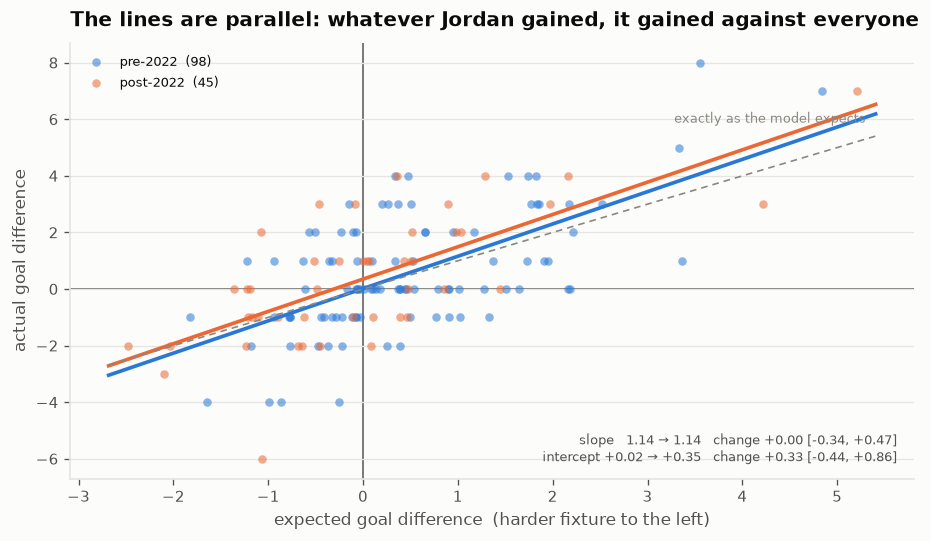

In [16]:
# THE question: given the opponent, how much better is Jordan? Every match, not
# four bins -- bins of 6 to 37 matches wobble, and the wobble reads as a finding.
# A fit per era answers both "how much better" (the intercept) and "does it
# depend on the opponent" (the slope).
fits = {}
for e in ("pre", "post"):
    d = mt[mt.era == e]
    fits[e] = np.polyfit(d.expected_gd, d.gd, 1)      # slope, intercept

draws = []
for _ in range(3000):
    p = {}
    for e in ("pre", "post"):
        s_ = pd.concat([BLK[e][i] for i in rng.integers(0, len(BLK[e]), len(BLK[e]))])
        if s_.expected_gd.nunique() > 2:
            p[e] = np.polyfit(s_.expected_gd, s_.gd, 1)
    if len(p) == 2:
        draws.append([p["post"][0] - p["pre"][0], p["post"][1] - p["pre"][1]])
draws = np.array(draws)
d_slope = (fits["post"][0] - fits["pre"][0], *np.percentile(draws[:, 0], [2.5, 97.5]))
d_int = (fits["post"][1] - fits["pre"][1], *np.percentile(draws[:, 1], [2.5, 97.5]))

fig, ax = plt.subplots(figsize=(7.6, 4.4))
xs = np.linspace(mt.expected_gd.min() - 0.2, mt.expected_gd.max() + 0.2, 50)
for e, col in (("pre", viz.BLUE), ("post", viz.ORANGE)):
    d = mt[mt.era == e]
    ax.scatter(d.expected_gd, d.gd, s=26, color=col, alpha=0.55, linewidths=0,
               label=f"{e}-2022  ({len(d)})")
    ax.plot(xs, np.polyval(fits[e], xs), color=col, lw=2.2)
ax.plot(xs, xs, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
ax.annotate("exactly as the model expects", xy=(xs[-1], xs[-1]), xytext=(-6, 8),
            ha="right", textcoords="offset points", fontsize=8,
            color=viz.INK_MUTED)
ax.axhline(0, color=viz.INK_2, lw=0.9, zorder=0)
ax.axvline(0, color=viz.INK_2, lw=0.9, zorder=0)
ax.set_xlabel("expected goal difference  (harder fixture to the left)")
ax.set_ylabel("actual goal difference")
ax.set_title("The lines are parallel: whatever Jordan gained, it gained "
             "against everyone")
ax.legend(fontsize=8, loc="upper left")
ax.annotate(f"slope   {fits['pre'][0]:.2f} → {fits['post'][0]:.2f}"
            f"   change {d_slope[0]:+.2f} [{d_slope[1]:+.2f}, {d_slope[2]:+.2f}]"
            f"\nintercept {fits['pre'][1]:+.2f} → {fits['post'][1]:+.2f}"
            f"   change {d_int[0]:+.2f} [{d_int[1]:+.2f}, {d_int[2]:+.2f}]",
            xy=(0.98, 0.04), xycoords="axes fraction", ha="right", fontsize=8,
            color=viz.INK_2)
viz.despine(ax)
plt.show()

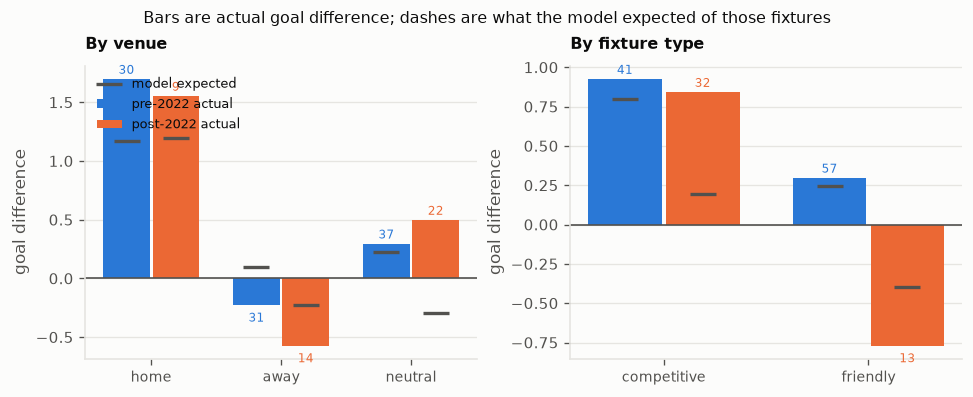

In [17]:
# Venue and fixture type. Comparing WITHIN an era is clean -- whatever lag the
# model carries applies to the whole era equally -- so the contrast between
# venues is fair even though the across-era residual is not.
fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.2))
for ax, col_, order in ((axes[0], "venue", ["home", "away", "neutral"]),
                        (axes[1], "kind", ["competitive", "friendly"])):
    x = np.arange(len(order))
    for off, e, c in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
        d = mt[mt.era == e]
        act = [d[d[col_] == k].gd.mean() for k in order]
        exp = [d[d[col_] == k].expected_gd.mean() for k in order]
        n_ = [int((d[col_] == k).sum()) for k in order]
        ax.bar(x + off, act, width=0.36, color=c, label=f"{e}-2022 actual")
        ax.scatter(x + off, exp, marker="_", s=260, color=viz.INK_2, zorder=4,
                   label="model expected" if e == "pre" else None)
        for xi_, v, nn in zip(x + off, act, n_):
            ax.annotate(f"{nn}", (xi_, v), xytext=(0, 3 if v >= 0 else -10),
                        ha="center", textcoords="offset points", fontsize=7,
                        color=c)
    ax.axhline(0, color=viz.INK_2, lw=1.0)
    ax.set_xticks(x)
    ax.set_xticklabels(order, fontsize=8.5)
    ax.set_ylabel("goal difference")
    viz.despine(ax)
axes[0].set_title("By venue", fontsize=9.5)
axes[1].set_title("By fixture type", fontsize=9.5)
axes[0].legend(fontsize=7.5, loc="upper left")
fig.suptitle("Bars are actual goal difference; dashes are what the model "
             "expected of those fixtures", fontsize=9.5)
plt.show()

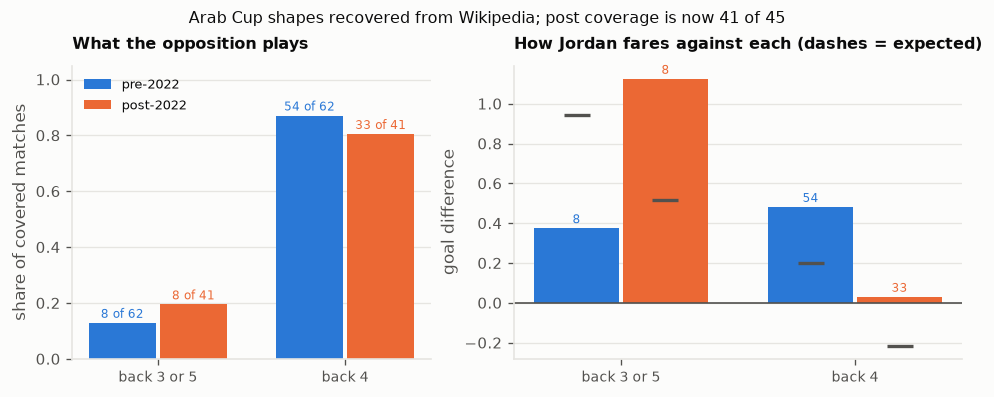

In [18]:
# How the opposition sets up. The gap that made this unusable is now closed:
# FBref has no Arab Cup, so opp_formation was null for ten post-era matches and
# they were Jordan's easiest block. wiki_arabcup now derives the opposition's
# shape from the same Football box that supplied Jordan's lineup, taking post
# coverage from 35/45 to 41/45. Four post matches remain uncovered.
cov = mt.assign(has=mt.opp_formation.notna())
ol = mt.dropna(subset=["opp_line"])

fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.2),
                         gridspec_kw={"width_ratios": [1, 1.25]})
a = axes[0]
t = pd.crosstab(ol.opp_line, ol.era, normalize="columns").reindex(columns=["pre", "post"])
n_ = pd.crosstab(ol.opp_line, ol.era).reindex(columns=["pre", "post"])
x = np.arange(len(t))
for off, e, c in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    a.bar(x + off, t[e], width=0.36, color=c, label=f"{e}-2022")
    for xi_, v, nn in zip(x + off, t[e], n_[e]):
        a.annotate(f"{int(nn)} of {int(n_[e].sum())}", (xi_, v), xytext=(0, 3),
                   ha="center", textcoords="offset points", fontsize=7, color=c)
a.set_xticks(x)
a.set_xticklabels(t.index, fontsize=8.5)
a.set_ylim(0, 1.05)
a.set_ylabel("share of covered matches")
a.set_title("What the opposition plays", fontsize=9.5)
a.legend(fontsize=8)
viz.despine(a)

b = axes[1]
g = (ol.groupby(["opp_line", "era"], observed=True)
     .agg(n=("gd", "size"), gd=("gd", "mean"), exp=("expected_gd", "mean"))
     .reset_index())
x = np.arange(2)
for off, e, c in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    d = g[g.era == e].set_index("opp_line").reindex(t.index)
    b.bar(x + off, d.gd.values, width=0.36, color=c, label=f"{e}-2022")
    b.scatter(x + off, d.exp.values, marker="_", s=260, color=viz.INK_2, zorder=4)
    for xi_, v, nn in zip(x + off, d.gd.values, d.n.values):
        if np.isfinite(v):
            b.annotate(f"{int(nn)}", (xi_, v), xytext=(0, 3 if v >= 0 else -10),
                       ha="center", textcoords="offset points", fontsize=7, color=c)
b.axhline(0, color=viz.INK_2, lw=1.0)
b.set_xticks(x)
b.set_xticklabels(t.index, fontsize=8.5)
b.set_ylabel("goal difference")
b.set_title("How Jordan fares against each (dashes = expected)", fontsize=9.5)
viz.despine(b)
fig.suptitle("Arab Cup shapes recovered from Wikipedia; post coverage is now "
             "41 of 45", fontsize=9.5)
plt.show()

**The opponents got much harder — twice as fast as Jordan improved.** Expected
goal difference is a *difference*, so a line of it falling cannot say which side
moved. Backing the opponent out of it, with the model's own home-advantage term
(0.27) removed:

| | pre | post | change |
|---|---|---|---|
| Jordan's strength | 0.70 | 1.11 | **+0.41** |
| the opponent's | 0.22 | 1.06 | **+0.84** |
| the gap between them | +0.48 | +0.02 | −0.45 |

The blue line is notebook 01's trace, sampled at match dates; the orange is who
was on the other side. The narrowing gap *understates* the hardening, because
Jordan's own rise is pushing it back open. This is not a scheduling-mix effect —
holding the venue mix fixed gives +0.25 to +0.98, and opponent strength rises
inside every venue category.

**The jaggedness is the calendar, not noise.** Jordan's schedule runs in three
modes and they face completely different opposition: qualifying groups average
**−0.34** and reach down to Pakistan at −3.99 and Cambodia at −3.73; friendlies
average +0.66; finals average **+1.20** and reach up to Argentina at +3.79.
Qualifying also carries much the widest spread (sd 1.60 against 0.90 and 0.95),
because AFC groups put minnows and real sides in the same campaign. Every trough
in the orange line is a qualifying window.

**And it was partly chosen.** Qualifiers are drawn, so meeting better teams is
partly a consequence of going further. But the *friendlies* hardened too,
**+0.24 to −0.39**, and friendlies are arranged. Somebody decided to play better
opposition.

**Whatever Jordan gained, it gained against everyone equally.** Fitting every
match rather than binning: the slope is **1.14 in both eras** — change **+0.00,
95% [−0.34, +0.48]** — and only the intercept moves, +0.02 to +0.35. Parallel
lines.

🚨 **Read the slope, not the intercept.** This fit establishes *uniformity*, not
improvement: the intercept's own change is **+0.33, 95% [−0.43, +0.86]**, which
spans zero on twenty-odd six-month blocks. That Jordan improved is notebook 01's
finding, where the strength model puts it at **+0.717 [+0.203, +1.220]**. What
this panel adds is that the gain does not depend on who the opponent is.

The bins said otherwise, and were wrong to: cells of six to thirty-seven matches
wobble enough to look like a pattern, and the continuous fit over all 143 says
there is none.

A uniform goal-difference gain still converts into *more extra points* against
weak teams than strong ones, because points are nonlinear in goal difference.
That is why Jordan looks so much more ruthless against poor sides — 2.14 to 2.67
points a match — without having improved differentially against them.

**Nobody changes shape for Jordan.** Teams line up against them with a back four
almost always, and the count of back-three opponents is **8 before 2022 and 8
after** — identical. The *share* rises only because the denominator shrank.

This was nearly unusable: FBref carries no Arab Cup, so opp_formation was absent
for ten of the post era's forty-five matches, and they were not a random ten —
Jordan's easiest block, the one it won most heavily. The opposition's lineup was
sitting in the same Wikipedia box that already supplied Jordan's, so the shape is
derivable the same way, and post coverage is now **41 of 45**. All ten Arab Cup
opponents played a back four.

🚨 Four post-era matches are still missing and they still lean easy (mean
expected goal difference +0.99 against −0.07 for the covered ones), so read the
right-hand panel as a description rather than an estimate.

## 3. The scorers

Section 2 asked who Jordan played. This asks who did the scoring, and whether
they were good or merely picked.

Six questions:

1. **Who scored, before and after?**
2. **How were they treated** — did the scorers get more of the playing time?
3. **Did they score faster, or just more often?** Goals per 90 separates a better
   forward from a forward who is simply on the pitch longer.
4. **Do their goals justify their minutes?** A player's share of the goals
   against his share of the time.
5. **What kind of goals?** Penalties flatter a scoring record.
6. **Did the scoring concentrate more than the squad did?** — the check that
   decides whether any of the above is a fact about scoring at all.

Assists would belong here and are excluded: recorded on **35%** of pre-2022
open-play goals against **70%** after, with the boundary on the treatment date.
Shots are worse — zero in 2015-18 and 2020-23, gated by competition exactly like
possession.

In [19]:
# Per player, per era: minutes, goals, and the rate. Everything below is built
# from this one frame.
ja_e = ja.dropna(subset=["player_id"]).assign(
    era=ja.match_id.map(mt.set_index("match_id").era)).dropna(subset=["era"])
mins = (ja_e.groupby(["player_id", "era"]).Min.sum().unstack("era")
        .reindex(columns=["pre", "post"]).fillna(0))
gls = (gj.groupby(["scorer_player_id", "era"]).size().unstack("era")
       .reindex(columns=["pre", "post"]).fillna(0))
sc = mins.join(gls, rsuffix="_g").fillna(0)
sc["name"] = sc.index.map(NAMES)
TEAM_MIN = ja_e.groupby("era").Min.sum()
TEAM_GLS = gj.groupby("era").size()
MIN_FLOOR = 270          # three full matches; below this a per-90 is noise
for e in ("pre", "post"):
    sc[f"share_min_{e}"] = sc[e] / TEAM_MIN[e]
    sc[f"share_gls_{e}"] = sc[f"{e}_g"] / TEAM_GLS[e]
    sc[f"p90_{e}"] = np.where(sc[e] >= MIN_FLOOR, sc[f"{e}_g"] / sc[e] * 90, np.nan)
sc["total_g"] = sc.pre_g + sc.post_g
TOP = sc.sort_values("total_g", ascending=False).head(10)

In [20]:
tab = (gj.pivot_table(index="scorer_player_id", columns="era",
                      values="match_id", aggfunc="size")
       .reindex(columns=["pre", "post"]).fillna(0).astype(int))
tab["total"] = tab.sum(axis=1)
tab.insert(0, "player", tab.index.map(NAMES))
top = tab.sort_values("total", ascending=False).head(10)
# the table and the top-three shares are both drawn by the next cell

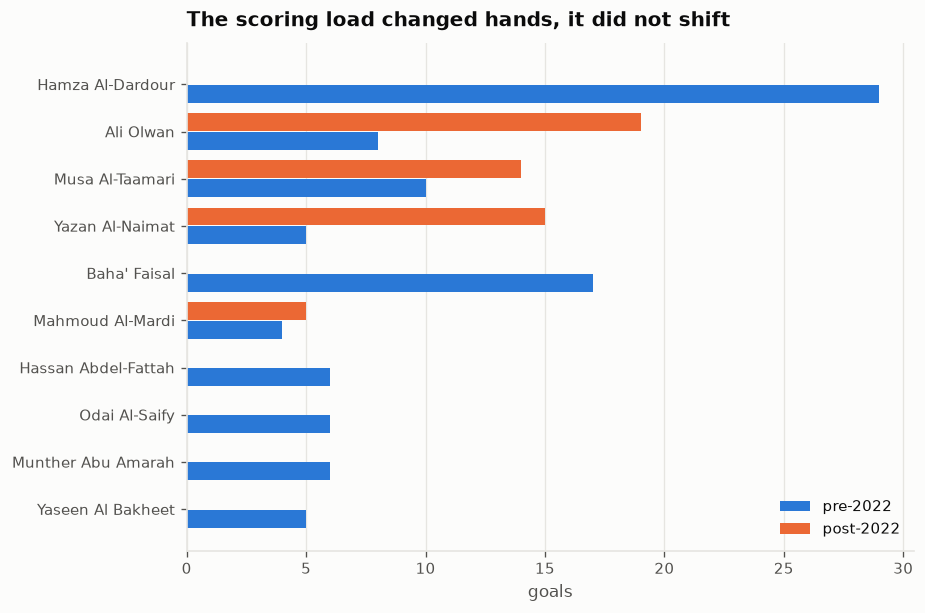

In [21]:
fig, ax = plt.subplots(figsize=(7.6, 5.0))
d = top.iloc[::-1]
y = np.arange(len(d))
ax.barh(y - 0.2, d.pre, height=0.38, color=viz.BLUE, label="pre-2022")
ax.barh(y + 0.2, d.post, height=0.38, color=viz.ORANGE, label="post-2022")
ax.set_yticks(y); ax.set_yticklabels(d.player)
ax.set_xlabel("goals")
ax.set_title("The scoring load changed hands, it did not shift")
ax.legend(loc="lower right")
viz.despine(ax)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.show()

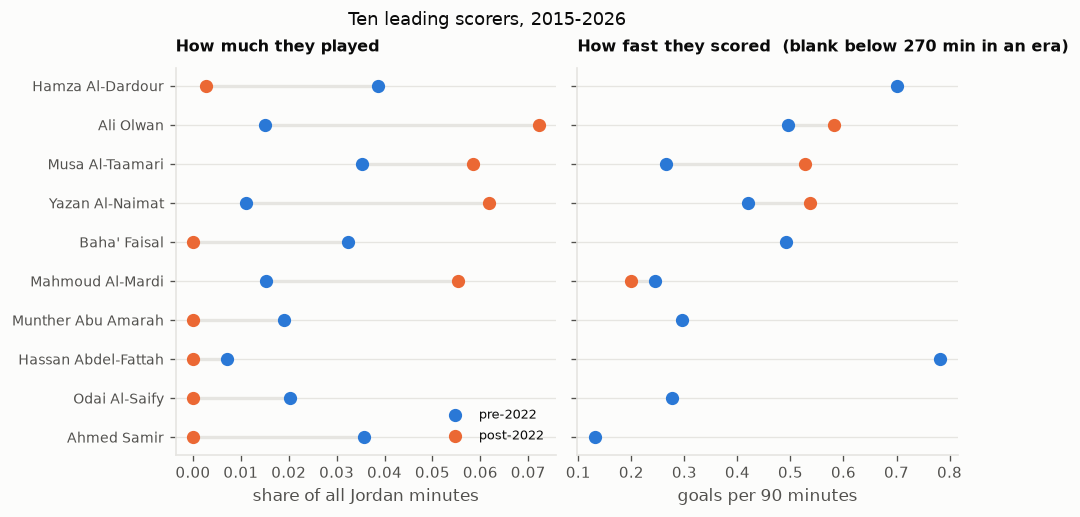

In [22]:
# How the scoring load was carried: minutes on the left, rate on the right, the
# same ten players in the same order, so a reader can see at a glance whether a
# man scored more because he played more or because he scored faster.
d = TOP.iloc[::-1]
y = np.arange(len(d))
fig, axes = plt.subplots(1, 2, figsize=(8.0, 4.2), sharey=True)

a = axes[0]
for i, r in enumerate(d.itertuples()):
    a.plot([r.share_min_pre, r.share_min_post], [i, i], color=viz.GRID, lw=2.0,
           zorder=1, solid_capstyle="round")
a.scatter(d.share_min_pre, y, color=viz.BLUE, s=48, zorder=3, label="pre-2022")
a.scatter(d.share_min_post, y, color=viz.ORANGE, s=48, zorder=3, label="post-2022")
a.set_yticks(y)
a.set_yticklabels(d.name, fontsize=8.5)
a.set_xlabel("share of all Jordan minutes")
a.set_title("How much they played", fontsize=9.5)
a.legend(fontsize=8, loc="lower right")
viz.despine(a)

b = axes[1]
for i, r in enumerate(d.itertuples()):
    if np.isfinite(r.p90_pre) and np.isfinite(r.p90_post):
        b.plot([r.p90_pre, r.p90_post], [i, i], color=viz.GRID, lw=2.0, zorder=1)
b.scatter(d.p90_pre, y, color=viz.BLUE, s=48, zorder=3)
b.scatter(d.p90_post, y, color=viz.ORANGE, s=48, zorder=3)
b.set_xlabel("goals per 90 minutes")
b.set_title(f"How fast they scored  (blank below {MIN_FLOOR} min in an era)",
            fontsize=9.5)
viz.despine(b)
fig.suptitle("Ten leading scorers, 2015-2026", fontsize=11)
plt.show()

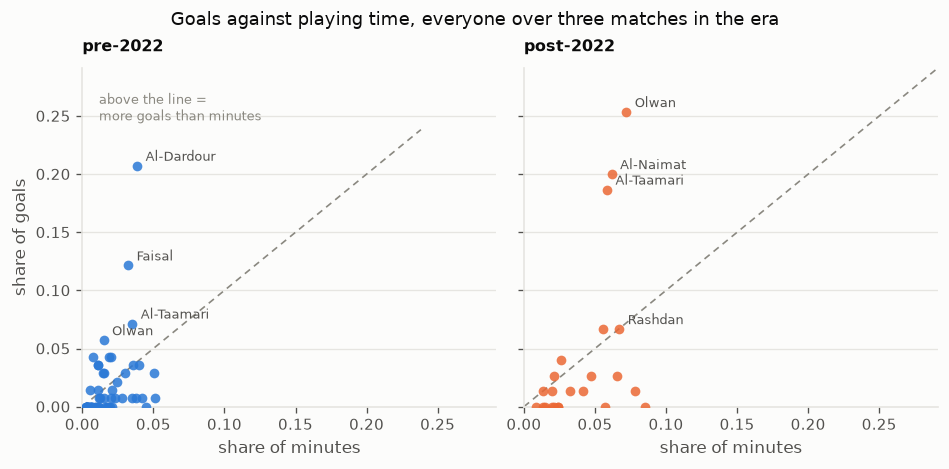

In [23]:
# Do the goals justify the minutes? On the diagonal a player takes exactly the
# share of the goals that he takes of the time. Above it he is doing more with
# what he gets.
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.8), sharex=True, sharey=True)
for ax, e, col in ((axes[0], "pre", viz.BLUE), (axes[1], "post", viz.ORANGE)):
    d = sc[sc[e] >= MIN_FLOOR]
    lim = max(d[f"share_min_{e}"].max(), d[f"share_gls_{e}"].max()) * 1.15
    ax.plot([0, lim], [0, lim], color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)),
            zorder=1)
    ax.scatter(d[f"share_min_{e}"], d[f"share_gls_{e}"], s=34, color=col,
               alpha=0.85, zorder=3, linewidths=0)
    for r in d.sort_values(f"share_gls_{e}", ascending=False).head(4).itertuples():
        ax.annotate(getattr(r, "name").split()[-1],
                    (getattr(r, f"share_min_{e}"), getattr(r, f"share_gls_{e}")),
                    xytext=(5, 3), textcoords="offset points", fontsize=7.5,
                    color=viz.INK_2)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("share of minutes")
    ax.set_title(f"{e}-2022", fontsize=9.5)
    viz.despine(ax)
axes[0].set_ylabel("share of goals")
axes[0].annotate("above the line =\nmore goals than minutes", xy=(0.04, 0.93),
                 xycoords="axes fraction", fontsize=7.5, color=viz.INK_MUTED,
                 va="top")
fig.suptitle("Goals against playing time, everyone over three matches in the era",
             fontsize=10.5)
plt.show()

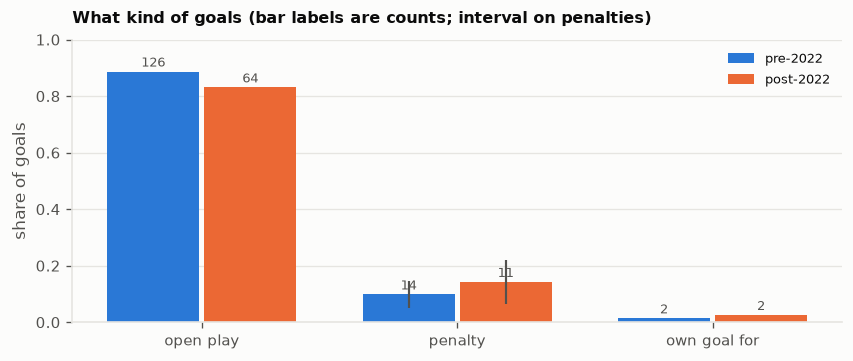

In [24]:
# What kind of goals? Penalties and own goals flatter a scoring record, so the
# open-play count is the one worth carrying forward.
# the FULL goals frame, not gj: an own goal for Jordan is scored by an opponent
# and so carries no Jordan player id, which would zero that bar out
gt = goals.assign(t=goals.type.fillna("open play"))
ORD = ["goal", "penalty_goal", "own_goal_for"]
kinds = (pd.crosstab(gt.t, gt.era, normalize="columns")
         .reindex(columns=["pre", "post"]).reindex(ORD).fillna(0))
cnt = (pd.crosstab(gt.t, gt.era).reindex(columns=["pre", "post"])
       .reindex(ORD).fillna(0))
kinds.index = cnt.index = ["open play", "penalty", "own goal for"]

fig, ax = plt.subplots(figsize=(7.0, 2.9))
x = np.arange(len(kinds))
tot = gt.groupby("era").size().reindex(["pre", "post"])
for off, e, col in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    ax.bar(x + off, kinds[e], width=0.36, color=col, label=f"{e}-2022")
    for xi_, v, n_ in zip(x + off, kinds[e], cnt[e]):
        ax.annotate(f"{int(n_)}", (xi_, v), xytext=(0, 3), ha="center",
                    textcoords="offset points", fontsize=7.5, color=viz.INK_2)
# an interval on the penalty share, since that is the one people read into
for i, (off, e) in enumerate(((-0.19, "pre"), (0.19, "post"))):
    p_ = kinds.loc["penalty", e]
    lo, hi = np.percentile([rng.binomial(int(tot[e]), p_) / tot[e]
                            for _ in range(4000)], [2.5, 97.5])
    ax.vlines(1 + off, lo, hi, color=viz.INK_2, lw=1.3)
ax.set_xticks(x)
ax.set_xticklabels(kinds.index)
ax.set_ylabel("share of goals")
ax.set_ylim(0, 1.0)
ax.set_title("What kind of goals (bar labels are counts; interval on penalties)",
             fontsize=9.5)
ax.legend(fontsize=8)
viz.despine(ax)
plt.show()

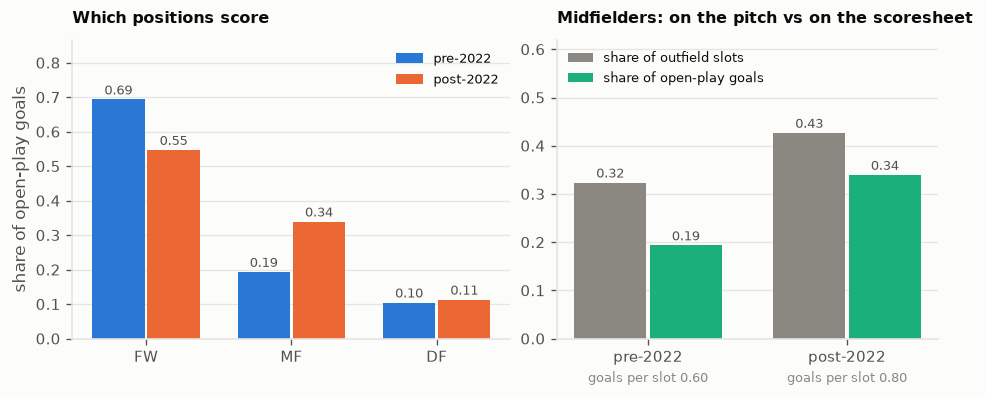

In [25]:
# WHERE the goals come from, open play only. The right panel is the test: a back
# three puts more midfielders on the pitch, so their share of the goals should
# rise for free. Slots first, then goals, then the ratio between them.
op = gj[~gj.type.eq("penalty_goal")]
pos = (pd.crosstab(op.scorer_position, op.era, normalize="columns")
       .reindex(columns=["pre", "post"]).reindex(["FW", "MF", "DF"]).fillna(0))
slots = (mt.groupby("era")[["n_df", "n_mf", "n_fw"]].sum()
         .reindex(["pre", "post"]))
slots = slots.div(slots.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2),
                         gridspec_kw={"width_ratios": [1.15, 1]})
a = axes[0]
x = np.arange(len(pos))
for off, e, col in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    a.bar(x + off, pos[e], width=0.36, color=col, label=f"{e}-2022")
    for xi_, v in zip(x + off, pos[e]):
        a.annotate(f"{v:.2f}", (xi_, v), xytext=(0, 3), ha="center",
                   textcoords="offset points", fontsize=7.5, color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(pos.index)
a.set_ylim(0, pos.values.max() * 1.25)
a.set_ylabel("share of open-play goals")
a.set_title("Which positions score", fontsize=9.5)
a.legend(fontsize=8)
viz.despine(a)

b = axes[1]
mf_slot = slots.n_mf
mf_goal = pos.loc["MF"]
xx = np.arange(2)
b.bar(xx - 0.19, mf_slot.values, width=0.36, color=viz.INK_MUTED,
      label="share of outfield slots")
b.bar(xx + 0.19, mf_goal.values, width=0.36, color=viz.AQUA,
      label="share of open-play goals")
for i in range(2):
    b.annotate(f"{mf_slot.iloc[i]:.2f}", (xx[i] - 0.19, mf_slot.iloc[i]),
               xytext=(0, 3), ha="center", textcoords="offset points",
               fontsize=7.5, color=viz.INK_2)
    b.annotate(f"{mf_goal.iloc[i]:.2f}", (xx[i] + 0.19, mf_goal.iloc[i]),
               xytext=(0, 3), ha="center", textcoords="offset points",
               fontsize=7.5, color=viz.INK_2)
    b.annotate(f"goals per slot {mf_goal.iloc[i] / mf_slot.iloc[i]:.2f}",
               (xx[i], 0), xytext=(0, -26), ha="center",
               textcoords="offset points", fontsize=7.5, color=viz.INK_MUTED)
b.set_xticks(xx)
b.set_xticklabels(["pre-2022", "post-2022"])
b.set_ylim(0, 0.62)
b.set_title("Midfielders: on the pitch vs on the scoresheet", fontsize=9.5)
b.legend(fontsize=7.5, loc="upper left")
viz.despine(b)
plt.show()

**They were picked far more, and they also got better.** Both halves matter, and
they are different claims.

Ali Olwan goes from **1.5% to 7.2%** of Jordan's minutes, Al-Naimat from 1.1% to
6.2% — roughly five times the playing time each. That is selection. But the rate
moved too: Al-Taamari **doubles**, 0.27 to 0.53 goals per 90, and Olwan and
Al-Naimat both improve on an already decent number. Mahmoud Al-Mardi is the
counter-example, taking a large share of the minutes while his rate drifts down.

**The scoring is not propped up by penalties**, though the share does rise —
9.9% to 14.3%, on 14 and 11 goals, an interval far too wide to call a change.

**And the penalties are not what put midfielders on the scoresheet.**
Midfielders take about half the spot kicks in *both* eras, and the midfield share
of **open-play** goals rises **+0.146, 95% [+0.045, +0.332]** against +0.148
[+0.038, +0.329] for all goals — the same number. Penalties explain none of it,
which is why the position figure drops them.

**What does explain part of it is the formation.** Section 1's back three puts
more midfielders on the pitch: they go from **32%** of the outfield to **43%**.
But that is not the whole story either — their goals per outfield slot rises
**0.60 → 0.80**. More midfielders, *and* each one scoring more often than a
midfielder used to. Both, not either.

In [26]:
pre_s = gj[gj.era == "pre"].scorer_player_id
post_s = gj[gj.era == "post"].scorer_player_id
n_post = len(post_s)

def profile(s):
    vc = s.value_counts(); p = vc / vc.sum()
    return np.array([len(vc), p.iloc[0], p.head(3).sum(), (p ** 2).sum()])

obs = profile(post_s)
draws = np.array([profile(pre_s.sample(n_post, replace=False,
                                       random_state=int(rng.integers(1e9))))
                  for _ in range(4000)])

LABELS = ["distinct scorers", "top-1 share", "top-3 share", "HHI"]
rows = []
for i, lab in enumerate(LABELS):
    lo, hi = np.percentile(draws[:, i], [2.5, 97.5])
    rows.append({"measure": lab, "post": obs[i], "pre_lo": lo, "pre_hi": hi,
                 "verdict": "outside" if not (lo <= obs[i] <= hi) else "inside"})
rar = pd.DataFrame(rows)   # drawn by the next two cells
RAR_N = (n_post, int(obs[0]), len(pre_s), pre_s.nunique())

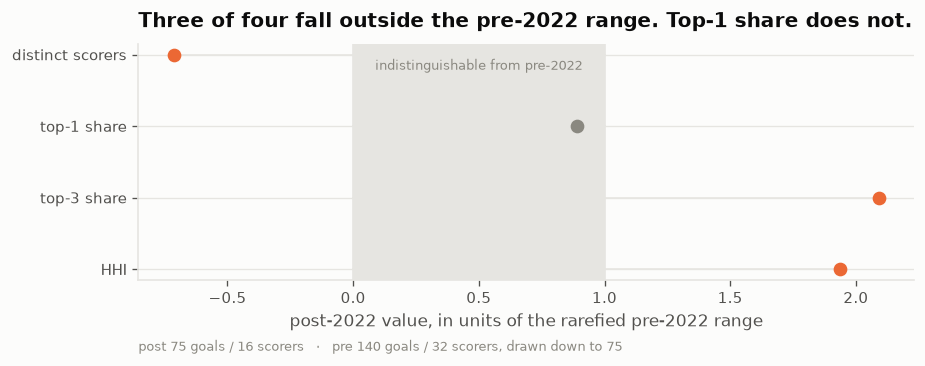

In [27]:
# Four measures, four different units. Put them on one axis by expressing the
# post-2022 value in units of its OWN rarefied pre-2022 range: 0 is that range's
# floor, 1 its ceiling. Inside the band means indistinguishable from a pre-2022
# sample of the same size.
fig, ax = plt.subplots(figsize=(7.6, 2.9))
d = rar.iloc[::-1].reset_index(drop=True)
z = (d.post - d.pre_lo) / (d.pre_hi - d.pre_lo)
ax.axvspan(0, 1, color=viz.GRID, zorder=0)
ax.annotate("indistinguishable from pre-2022", xy=(0.5, 1.0),
            xycoords=("data", "axes fraction"), xytext=(0, -9),
            textcoords="offset points", ha="center", va="top", fontsize=8,
            color=viz.INK_MUTED)
for i, (v, verdict) in enumerate(zip(z, d.verdict)):
    col = viz.ORANGE if verdict == "outside" else viz.INK_MUTED
    ax.plot([min(v, 0), max(v, 1)], [i, i], color=viz.GRID, lw=1.0, zorder=1)
    ax.scatter([v], [i], color=col, s=52, zorder=3)
ax.set_yticks(range(len(d)))
ax.set_yticklabels(d.measure)
ax.set_xlabel("post-2022 value, in units of the rarefied pre-2022 range")
ax.set_title("Three of four fall outside the pre-2022 range. Top-1 share does not.")
ax.annotate(f"post {RAR_N[0]} goals / {RAR_N[1]} scorers   ·   "
            f"pre {RAR_N[2]} goals / {RAR_N[3]} scorers, drawn down to {RAR_N[0]}",
            xy=(0, -0.30), xycoords="axes fraction", fontsize=8, color=viz.INK_MUTED)
viz.despine(ax)
plt.show()

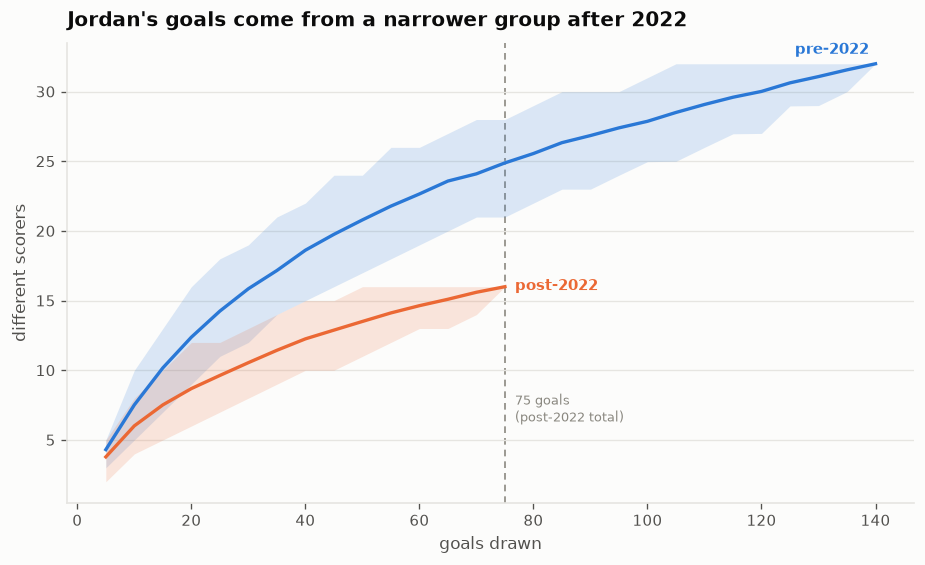

In [28]:
# Rarefaction curve: how many scorers a sample of k goals yields, pre vs post.
def curve(s, ks, reps=400):
    out = []
    for k in ks:
        if k > len(s):
            out.append((np.nan, np.nan, np.nan)); continue
        v = [s.sample(k, replace=False,
                      random_state=int(rng.integers(1e9))).nunique()
             for _ in range(reps)]
        out.append((np.mean(v), *np.percentile(v, [2.5, 97.5])))
    return np.array(out)

ks = np.arange(5, len(pre_s) + 1, 5)
c_pre = curve(pre_s, ks)
ks_post = np.arange(5, n_post + 1, 5)
c_post = curve(post_s, ks_post)

fig, ax = plt.subplots(figsize=(7.6, 4.6))
ax.fill_between(ks, c_pre[:, 1], c_pre[:, 2], color=viz.BLUE, alpha=0.16, lw=0)
ax.plot(ks, c_pre[:, 0], color=viz.BLUE, label="pre-2022")
ax.fill_between(ks_post, c_post[:, 1], c_post[:, 2], color=viz.ORANGE, alpha=0.16, lw=0)
ax.plot(ks_post, c_post[:, 0], color=viz.ORANGE, label="post-2022")
ax.axvline(n_post, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)
ax.annotate(f"{n_post} goals\n(post-2022 total)", xy=(n_post, 6),
            xytext=(6, 0), textcoords="offset points",
            fontsize=8, color=viz.INK_MUTED, va="bottom")
ax.annotate("pre-2022", xy=(ks[-1], c_pre[-1, 0]), xytext=(-4, 6),
            textcoords="offset points", color=viz.BLUE, fontsize=9,
            ha="right", fontweight="bold")
ax.annotate("post-2022", xy=(ks_post[-1], c_post[-1, 0]), xytext=(6, -2),
            textcoords="offset points", color=viz.ORANGE, fontsize=9,
            fontweight="bold")
ax.set_xlabel("goals drawn"); ax.set_ylabel("different scorers")
ax.set_title("Jordan's goals come from a narrower group after 2022")
viz.despine(ax)
plt.show()

In [29]:
# Rarefaction fixed the goal count. This fixes the player count: allocate each
# era's goals across players in proportion to the minutes they ACTUALLY played,
# and ask whether real scoring is more concentrated than that -- and whether the
# gap moved. If the gap is the same in both eras, the narrowing is section 1's,
# not a fact about scoring.
def gprofile(c):
    c = np.asarray(c, float)
    p = c[c > 0] / c[c > 0].sum()
    return {"distinct scorers": float(len(p)),
            "top-3 share": float(np.sort(p)[-3:].sum()),
            "HHI": float((p ** 2).sum())}

era_of = mt.set_index("match_id").era
jam = ja.assign(era=ja.match_id.map(era_of)).dropna(subset=["era"])
null = []
for e in ("pre", "post"):
    w = jam[jam.era == e].groupby("player_id").Min.sum()
    w = (w[w > 0] / w[w > 0].sum()).values
    g = gj[gj.era == e]
    obs = gprofile(g.scorer_player_id.value_counts().values)
    sim = pd.DataFrame([gprofile(rng.multinomial(len(g), w / w.sum()))
                        for _ in range(3000)])
    for k, v in obs.items():
        lo, hi = np.percentile(sim[k], [2.5, 97.5])
        null.append({"era": e, "measure": k, "observed": v,
                     "implied": sim[k].mean(), "lo": lo, "hi": hi,
                     "n_players": len(w), "ratio": v / sim[k].mean()})
null = pd.DataFrame(null)

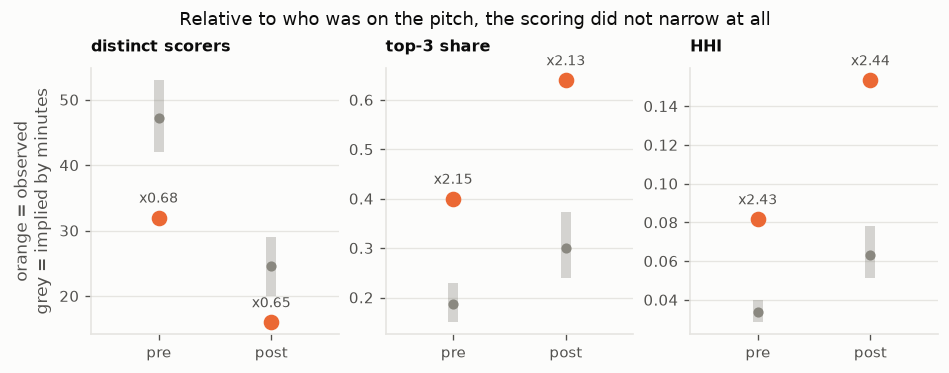

In [30]:
MEAS = ["distinct scorers", "top-3 share", "HHI"]
fig, axes = plt.subplots(1, 3, figsize=(7.8, 3.0))
for ax, k in zip(axes, MEAS):
    d = null[null.measure == k].set_index("era").reindex(["pre", "post"])
    x = np.arange(2)
    ax.vlines(x, d.lo, d.hi, color=viz.INK_MUTED, lw=6, alpha=0.35)
    ax.scatter(x, d.implied, color=viz.INK_MUTED, s=26, zorder=3)
    ax.scatter(x, d.observed, color=viz.ORANGE, s=70, zorder=4)
    for xi, r in zip(x, d.ratio):
        ax.annotate(f"x{r:.2f}", (xi, d.observed.iloc[xi]), xytext=(0, 9),
                    ha="center", textcoords="offset points", fontsize=8.5,
                    color=viz.INK_2)
    ax.set_xticks(x)
    ax.set_xticklabels(["pre", "post"])
    ax.set_xlim(-0.6, 1.6)
    ax.set_title(k, fontsize=9.5)
    viz.despine(ax)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("orange = observed\ngrey = implied by minutes")
fig.suptitle("Relative to who was on the pitch, the scoring did not narrow at all",
             fontsize=11)
plt.show()

**The old top two disappear** — not reduced roles, zero goals. **The new top
three were already scoring** before 2022 and then roughly double or triple;
Al-Taamari is in the top three of *both* eras, so "Jordan replaced its forwards"
would be an overstatement.

At any common number of goals the post era uses fewer scorers, and that is real.
🚨 **But it is not one man** — top-1 share sits *inside* the rarefied range, so
"one player carries them" is not supportable.

🚨 **And the narrowing is not a fact about scoring.** Allocating each era's goals
in proportion to the minutes actually played, Jordan's scoring is about **2.4×**
more concentrated than minutes imply — *the same multiple before and after 2022*.
The distribution's shape did not change; what changed is how few men were on the
pitch, and how good the few were.

## 4. The goals

Not who scored but when, and what the scoreboard said. Reconstructed in
`JordanData/match_state.py` from goal minutes on **both** sides, including the
ten Arab Cup matches recovered from Wikipedia that FBref does not carry.

Coverage is 155 of 174 matches; the cell prints the count inside this window. The
gap is FBref reports with no event feed, and it is **balanced across eras** —
which it was not before the Arab Cup was recovered, when the missing matches were
disproportionately Jordan's best.

In [31]:
ms = pd.read_csv(SQUAD / "match_state.csv", parse_dates=["date"])
ms = ms[(ms.date >= START) & ms.jordan_side.notna()].copy()
ms["era"] = np.where(ms.date < CUT, "pre", "post")
BUCK = ["1-15", "16-30", "31-45", "46-60", "61-75", "76-90"]
f_tot = ms[[f"for_{b}" for b in BUCK]].sum().values
a_tot = ms[[f"against_{b}" for b in BUCK]].sum().values
prof = pd.DataFrame({"window": BUCK,
                     "scored": f_tot / f_tot.sum(),
                     "conceded": a_tot / a_tot.sum()})
MS_N = (len(ms), int(f_tot.sum()), int(a_tot.sum()))   # drawn by the next cell

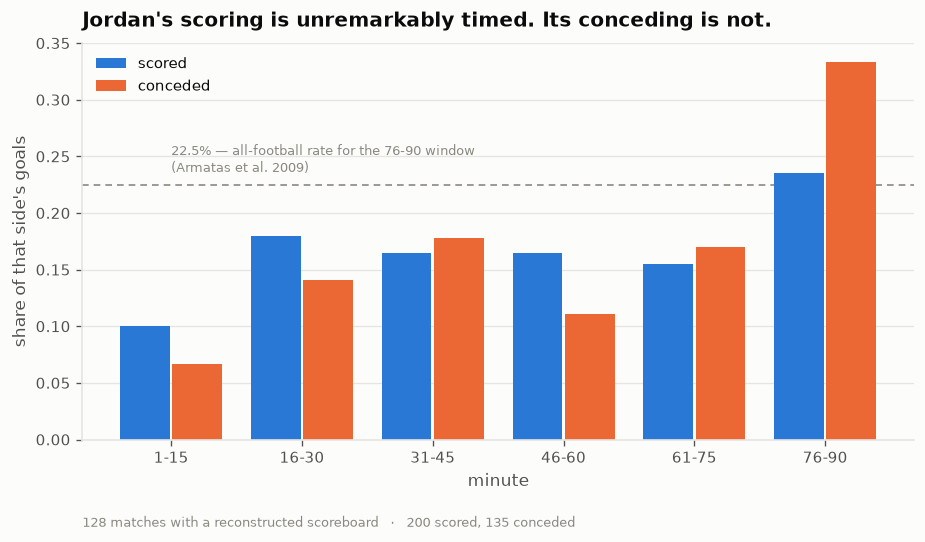

In [32]:
fig, ax = plt.subplots(figsize=(7.6, 4.4))
x = np.arange(len(BUCK))
ax.bar(x - 0.2, prof.scored, width=0.38, color=viz.BLUE, label="scored")
ax.bar(x + 0.2, prof.conceded, width=0.38, color=viz.ORANGE, label="conceded")
ax.axhline(0.225, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)
ax.annotate("22.5% — all-football rate for the 76-90 window\n(Armatas et al. 2009)",
            xy=(0, 0.225), xytext=(0, 5), textcoords="offset points",
            fontsize=8, color=viz.INK_MUTED, va="bottom")
ax.set_xticks(x); ax.set_xticklabels(BUCK)
ax.set_xlabel("minute"); ax.set_ylabel("share of that side's goals")
ax.set_title("Jordan's scoring is unremarkably timed. Its conceding is not.")
ax.annotate(f"{MS_N[0]} matches with a reconstructed scoreboard   ·   "
            f"{MS_N[1]} scored, {MS_N[2]} conceded",
            xy=(0, -0.22), xycoords="axes fraction", fontsize=8, color=viz.INK_MUTED)
ax.legend(loc="upper left")
viz.despine(ax)
ax.grid(axis="x", visible=False); ax.grid(axis="y", visible=True)
plt.show()

Jordan's scoring sits on the all-football benchmark — the attack has no special
relationship with the clock. **The conceding column is the outlier: a third of
every goal Jordan concedes arrives in the last fifteen minutes**, about half
again what Armatas et al. (2009) expect.

This describes all 155 matches, **not** a change across 2022 — the era difference
there does not clear zero. A standing feature, and the clearest thing in the
notebook pointing at something to fix.

### Crossing when with in-what-state

"A third of goals conceded arrive after the 75th" fits two opposite stories: a
team that throws away leads, or one that gets put away in matches it was already
losing. Neither section settles it alone.

Crossing them does. Rates need **minutes at risk** per cell, not goal counts — a
team that spends the last fifteen minutes level has more chance to concede a
level-state goal simply by being there.

In [33]:
cells = pd.read_csv(SQUAD / "state_time_cells.csv")
cells = cells[cells.match_id.isin(set(mt.match_id))]          # 2015+ window
grid = (cells.groupby(["window", "state"])
        .agg(minutes=("minutes", "sum"), ga=("ga", "sum"), gf=("gf", "sum"))
        .reset_index())
grid["conceded_per90"] = grid.ga / grid.minutes * 90
grid["scored_per90"] = grid.gf / grid.minutes * 90
ORDER = ["1-15", "16-30", "31-45", "46-60", "61-75", "76-90"]

# rates and the minutes behind them are both drawn by the next cell

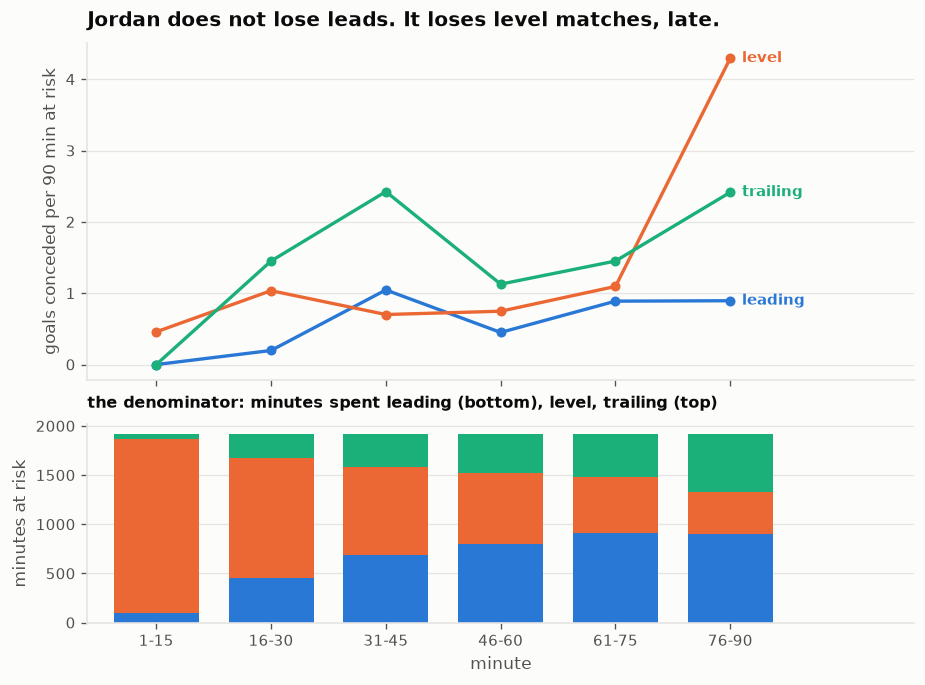

In [34]:
# A rate is a fraction, so both halves get drawn: the rate, and the minutes
# at risk underneath it. The late level cell is the smallest denominator on the
# chart, which is why its interval is wide.
fig, axes = plt.subplots(2, 1, figsize=(7.6, 5.6), sharex=True,
                         gridspec_kw={"height_ratios": [1.7, 1]})
x = np.arange(len(ORDER))
STATES = (("leading", viz.BLUE), ("level", viz.ORANGE), ("trailing", viz.AQUA))
a = axes[0]
for st, col in STATES:
    y = grid[grid.state == st].set_index("window").reindex(ORDER).conceded_per90
    a.plot(x, y.values, color=col, marker="o", label=st)
    a.annotate(st, xy=(x[-1], y.values[-1]), xytext=(7, 0),
               textcoords="offset points", color=col, fontsize=9,
               va="center", fontweight="bold")
a.set_ylabel("goals conceded per 90 min at risk")
a.set_title("Jordan does not lose leads. It loses level matches, late.")
viz.despine(a)

b = axes[1]
bot = np.zeros(len(ORDER))
for st, col in STATES:
    m = grid[grid.state == st].set_index("window").reindex(ORDER).minutes.fillna(0).values
    b.bar(x, m, bottom=bot, width=0.74, color=col, label=st)
    bot = bot + m
b.set_xticks(x)
b.set_xticklabels(ORDER)
b.set_xlim(-0.6, len(ORDER) + 0.6)
b.set_xlabel("minute")
b.set_ylabel("minutes at risk")
b.set_title("the denominator: minutes spent leading (bottom), level, trailing (top)",
            fontsize=9.5)
viz.despine(b)
plt.show()

The blue line is the control and it is flat: **with a lead, Jordan's conceding
rate in the last fifteen minutes is indistinguishable from the fifteen before
it.** Leads are not the problem.

The orange line is the finding. While **level**, the conceding rate roughly
quadruples going into the final window.

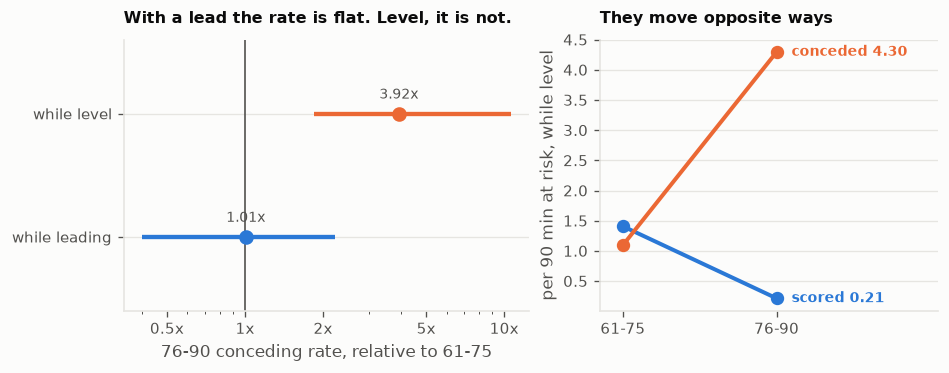

In [35]:
# The contrast, bootstrapped over matches in six-month blocks.
by_match = {m: d for m, d in cells.groupby("match_id")}
blocks = [d.match_id.tolist() for _, d in mt.groupby("blk")]

def rate(ms_, window, state, direction="ga"):
    d = pd.concat([by_match[m] for m in ms_ if m in by_match])
    s = d[(d.window == window) & (d.state == state)]
    return s[direction].sum() / s.minutes.sum() * 90 if s.minutes.sum() > 0 else np.nan

def ratio(ms_, state):
    late, before = rate(ms_, "76-90", state), rate(ms_, "61-75", state)
    return late / before if before and np.isfinite(before) else np.nan

allm = mt.match_id.tolist()
ratios = []
for st in ("leading", "level"):
    obs = ratio(allm, st)
    draws = []
    for _ in range(1500):
        pick = [m for i in rng.integers(0, len(blocks), len(blocks)) for m in blocks[i]]
        v = ratio(pick, st)
        if np.isfinite(v):
            draws.append(v)
    lo, hi = np.percentile(draws, [2.5, 97.5])
    ratios.append({"state": st, "obs": obs, "lo": lo, "hi": hi})
ratios = pd.DataFrame(ratios)

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0),
                         gridspec_kw={"width_ratios": [1.2, 1]})
a = axes[0]
for i, r in ratios.iterrows():
    col = viz.ORANGE if r.lo > 1 else viz.BLUE
    a.hlines(i, r.lo, r.hi, color=col, lw=2.6)
    a.scatter([r.obs], [i], color=col, s=60, zorder=3)
    a.annotate(f"{r.obs:.2f}x", (r.obs, i), xytext=(0, 9), ha="center",
               textcoords="offset points", fontsize=8.5, color=viz.INK_2)
a.axvline(1.0, color=viz.INK_2, lw=1.0)
a.set_xscale("log")
a.set_xticks([0.5, 1, 2, 5, 10])
a.set_xticklabels(["0.5x", "1x", "2x", "5x", "10x"])
a.set_yticks(range(len(ratios)))
a.set_yticklabels([f"while {v}" for v in ratios.state])
a.set_ylim(-0.6, len(ratios) - 0.4)
a.set_xlabel("76-90 conceding rate, relative to 61-75")
a.set_title("With a lead the rate is flat. Level, it is not.", fontsize=9.5)
viz.despine(a)

# The internal control: if level matches were simply frantic, BOTH rates rise.
b = axes[1]
for lab, direction, col in (("scored", "gf", viz.BLUE), ("conceded", "ga", viz.ORANGE)):
    v = [rate(allm, w, "level", direction) for w in ("61-75", "76-90")]
    b.plot([0, 1], v, color=col, lw=2.4, marker="o", ms=7, label=lab)
    b.annotate(f"{lab} {v[1]:.2f}", (1, v[1]), xytext=(9, 0), va="center",
               textcoords="offset points", fontsize=8.5, color=col,
               fontweight="bold")
b.set_xticks([0, 1])
b.set_xticklabels(["61-75", "76-90"])
b.set_xlim(-0.15, 2.05)
b.set_ylabel("per 90 min at risk, while level")
b.set_title("They move opposite ways", fontsize=9.5)
viz.despine(b)
b.grid(axis="x", visible=False)
plt.show()

So it is not that level matches get frantic and goals fly both ways. Jordan's
*scoring* rate while level collapses in the same window its conceding rate
quadruples. The asymmetry is the point.

Two checks before trusting it.

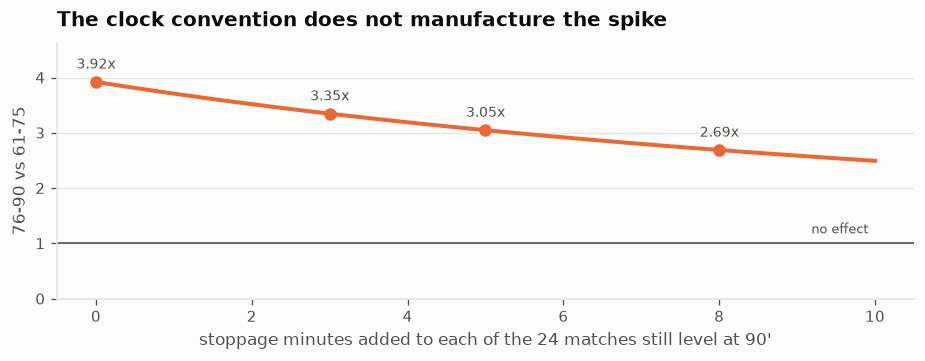

In [36]:
# The goal timelines, the same ones match_state builds its own table from.
from match_state import goal_timelines
TL = {m: v for m, v in goal_timelines().items() if m in set(mt.match_id)}
info = mt.set_index("match_id")

# Check 1 -- stoppage time. Minutes at risk stop at 90 for every match, but
# stoppage is always played, so the last window's rate is inflated for
# everyone. Adding it back can only shrink the effect. How much does it take?
level_at_90 = sum(1 for tl, _s, _x in TL.values()
                  if sum(d for m, d in tl if m <= 90) == 0)
lvl = grid[grid.state == "level"].set_index("window")
extra = np.linspace(0, 10, 101)
mins = lvl.loc["76-90", "minutes"] + extra * level_at_90
curve = (lvl.loc["76-90", "ga"] / mins * 90) / lvl.loc["61-75", "conceded_per90"]

fig, ax = plt.subplots(figsize=(7.6, 2.9))
ax.plot(extra, curve, color=viz.ORANGE, lw=2.4)
ax.axhline(1.0, color=viz.INK_2, lw=1.0)
ax.annotate("no effect", xy=(10, 1.0), xytext=(-4, 6), ha="right",
            textcoords="offset points", fontsize=8, color=viz.INK_2)
for e in (0, 3, 5, 8):
    v = (lvl.loc["76-90", "ga"] / (lvl.loc["76-90", "minutes"] + e * level_at_90)
         * 90) / lvl.loc["61-75", "conceded_per90"]
    ax.scatter([e], [v], color=viz.ORANGE, s=42, zorder=3)
    ax.annotate(f"{v:.2f}x", (e, v), xytext=(0, 8), ha="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.set_ylim(0, max(curve) * 1.18)
ax.set_xlabel(f"stoppage minutes added to each of the {level_at_90} matches still level at 90'")
ax.set_ylabel("76-90 vs 61-75")
ax.set_title("The clock convention does not manufacture the spike")
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

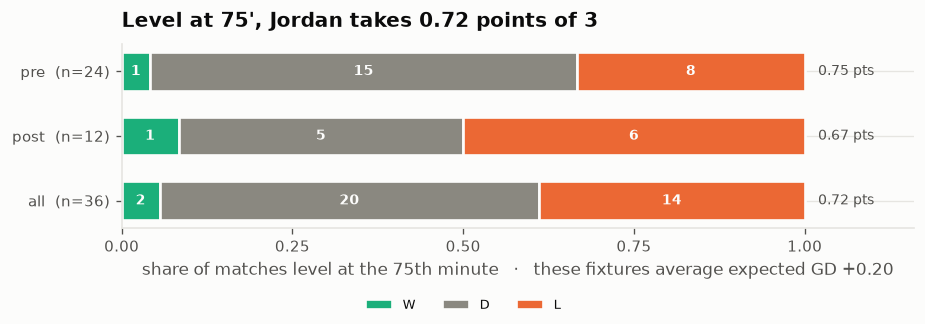

In [37]:
# Check 2 -- outcomes, independent of the rate arithmetic entirely.
rows = []
for mid, (tl, _s, _x) in TL.items():
    if sum(d for m, d in tl if m <= 75) != 0:      # level at 75' only
        continue
    dft = sum(d for _, d in tl)
    r = info.loc[mid]
    rows.append({"match_id": mid, "date": r.date, "era": r.era,
                 "opponent": r.opponent, "expected_gf": r.expected_gf,
                 "expected_ga": r.expected_ga, "expected_gd": r.expected_gd,
                 "pts": 3 if dft > 0 else (1 if dft == 0 else 0),
                 "result": "W" if dft > 0 else ("D" if dft == 0 else "L")})
L = pd.DataFrame(rows)
wdl = (pd.crosstab(L.era, L.result).reindex(columns=["W", "D", "L"]).fillna(0)
       .astype(int).reindex(["pre", "post"]))
wdl.loc["all"] = wdl.sum()

fig, ax = plt.subplots(figsize=(7.6, 2.6))
y = np.arange(len(wdl))[::-1]
left = np.zeros(len(wdl))
for res, col in (("W", viz.AQUA), ("D", viz.INK_MUTED), ("L", viz.ORANGE)):
    v = wdl[res].values / wdl.sum(axis=1).values
    ax.barh(y, v, left=left, height=0.6, color=col, label=res,
            edgecolor=viz.SURFACE, linewidth=1.6)
    for yy, (frac, n, l0) in enumerate(zip(v, wdl[res].values, left)):
        if n:
            ax.annotate(str(n), (l0 + frac / 2, y[yy]), ha="center", va="center",
                        fontsize=8.5, color=viz.SURFACE, fontweight="bold")
    left = left + v
for i, e in enumerate(wdl.index):
    d = L if e == "all" else L[L.era == e]
    ax.annotate(f"{d.pts.mean():.2f} pts", (1.0, y[i]), xytext=(8, 0), va="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.set_yticks(y)
ax.set_yticklabels([f"{e}  (n={int(n)})" for e, n in zip(wdl.index, wdl.sum(axis=1))])
ax.set_xlim(0, 1.16)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel(f"share of matches level at the 75th minute   ·   these fixtures "
              f"average expected GD {L.expected_gd.mean():+.2f}")
ax.set_title(f"Level at 75', Jordan takes {L.pts.mean():.2f} points of 3")
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=3,
           fontsize=8)
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

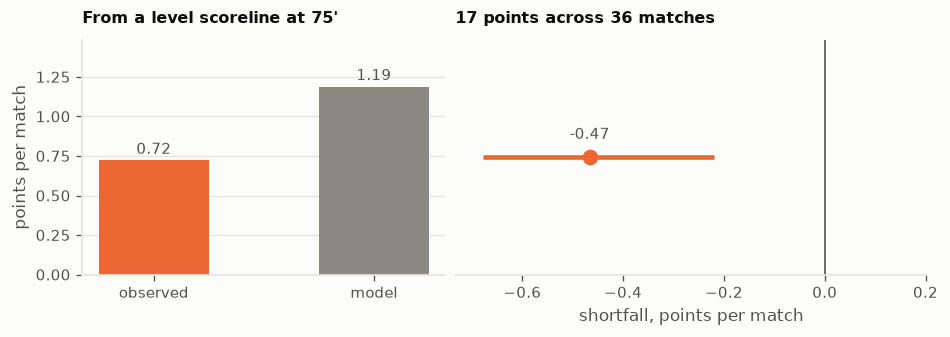

In [38]:
# Opponent-adjusted: what should a level scoreline at 75' be worth against
# THESE opponents? Simulate the remaining 15 minutes at each fixture's own
# model goal rates, which is the same adjustment gd_above_expected applies to
# a full match.
sim = []
for r in L.itertuples():
    kf = rng.poisson(r.expected_gf * 15 / 90, 40000)
    ka = rng.poisson(r.expected_ga * 15 / 90, 40000)
    d = kf - ka
    sim.append(np.where(d > 0, 3, np.where(d == 0, 1, 0)).mean())
sim = np.array(sim)
obs, exp = L.pts.mean(), sim.mean()
draws = [(L.pts.values[p].mean() - sim[p].mean())
         for p in (rng.integers(0, len(L), len(L)) for _ in range(5000))]
lo, hi = np.percentile(draws, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 2.7),
                         gridspec_kw={"width_ratios": [1, 1.3]})
a = axes[0]
a.bar([0, 1], [obs, exp], width=0.5, color=[viz.ORANGE, viz.INK_MUTED])
for i, v in enumerate((obs, exp)):
    a.annotate(f"{v:.2f}", (i, v), xytext=(0, 4), ha="center",
               textcoords="offset points", fontsize=9, color=viz.INK_2)
a.set_xticks([0, 1])
a.set_xticklabels(["observed", "model"])
a.set_ylim(0, max(obs, exp) * 1.25)
a.set_ylabel("points per match")
a.set_title("From a level scoreline at 75'", fontsize=9.5)
viz.despine(a)

b = axes[1]
b.hlines(0, lo, hi, color=viz.ORANGE, lw=2.8)
b.scatter([obs - exp], [0], color=viz.ORANGE, s=70, zorder=3)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.annotate(f"{obs - exp:+.2f}", (obs - exp, 0), xytext=(0, 11), ha="center",
           textcoords="offset points", fontsize=9, color=viz.INK_2)
b.set_ylim(-1, 1)
b.set_yticks([])
b.set_xlim(min(lo, 0) * 1.08, max(abs(lo), 0.05) * 0.30)
b.set_xlabel("shortfall, points per match")
b.set_title(f"{abs(obs - exp) * len(L):.0f} points across {len(L)} matches",
            fontsize=9.5)
viz.despine(b, keep=("bottom",))
plt.show()

A level scoreline at 75 minutes against these opponents should be worth ~1.2
points. Jordan takes **0.72** — roughly half a point per match short, interval
excluding zero, across 36 matches.

Not the clock convention: adding eight minutes of stoppage to every one of them
still leaves the spike at ~2.7×. Not opponent quality: the adjustment handles
that, and these are fixtures Jordan was favoured in.

🚨 **Partly the model, though.** The simulation setting that 1.2 draws goals at a
constant rate whatever the scoreboard says. How much that costs is measured in
**What we can still improve**; read the number with that attached.

### Did this change between the eras?

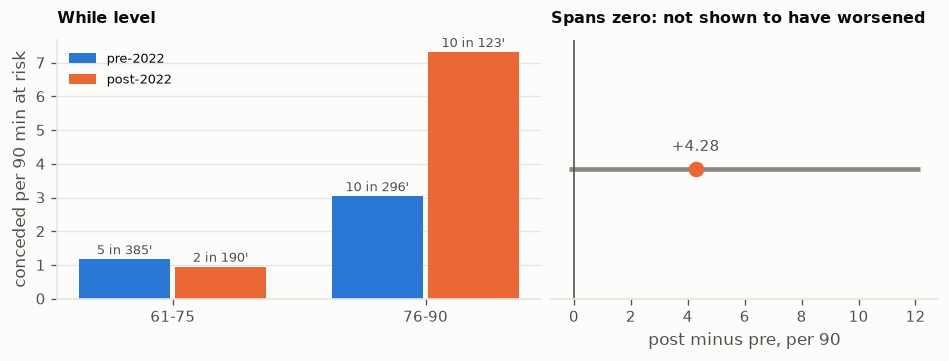

In [39]:
cells["era"] = cells.match_id.map(mt.set_index("match_id").era)
cellsum = []
for e in ("pre", "post"):
    d = cells[(cells.era == e) & (cells.state == "level")]
    for w in ("61-75", "76-90"):
        q = d[d.window == w]
        cellsum.append({"era": e, "window": w, "ga": int(q.ga.sum()),
                        "minutes": q.minutes.sum(),
                        "per90": q.ga.sum() / q.minutes.sum() * 90})
cellsum = pd.DataFrame(cellsum)

def late_level(ms_):
    return rate(ms_, "76-90", "level")

pre_m = mt[mt.era == "pre"].match_id.tolist()
post_m = mt[mt.era == "post"].match_id.tolist()
blk = {e: [d.match_id.tolist() for _, d in mt[mt.era == e].groupby("blk")]
       for e in ("pre", "post")}
draws = []
for _ in range(2000):
    s = {e: [m for i in rng.integers(0, len(blk[e]), len(blk[e])) for m in blk[e][i]]
         for e in ("pre", "post")}
    v = late_level(s["post"]) - late_level(s["pre"])
    if np.isfinite(v):
        draws.append(v)
lo, hi = np.percentile(draws, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 2.9),
                         gridspec_kw={"width_ratios": [1.25, 1]})
a = axes[0]
x = np.arange(2)
for off, e, col in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    d = cellsum[cellsum.era == e].set_index("window").reindex(["61-75", "76-90"])
    a.bar(x + off, d.per90.values, width=0.36, color=col, label=f"{e}-2022")
    for xi, (v, ga, mn) in enumerate(zip(d.per90, d.ga, d.minutes)):
        a.annotate(f"{ga} in {mn:.0f}'", (x[xi] + off, v), xytext=(0, 3),
                   ha="center", textcoords="offset points", fontsize=7.5,
                   color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(["61-75", "76-90"])
a.set_ylabel("conceded per 90 min at risk")
a.set_title("While level", fontsize=9.5)
a.legend(fontsize=8, loc="upper left")
viz.despine(a)
a.grid(axis="x", visible=False)

b = axes[1]
b.hlines(0, lo, hi, color=viz.INK_MUTED, lw=2.8)
dlate = late_level(post_m) - late_level(pre_m)
b.scatter([dlate], [0], color=viz.ORANGE, s=70, zorder=3)
b.annotate(f"{dlate:+.2f}", (dlate, 0), xytext=(0, 11), ha="center",
           textcoords="offset points", fontsize=9, color=viz.INK_2)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.set_ylim(-1, 1)
b.set_yticks([])
b.set_xlabel("post minus pre, per 90")
b.set_title("Spans zero: not shown to have worsened", fontsize=9.5)
viz.despine(b, keep=("bottom",))
plt.show()

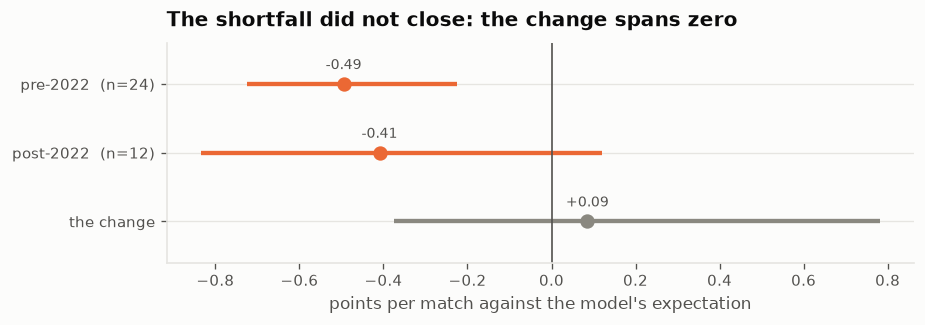

In [40]:
# The interpretable version: the points shortfall, by era.
L["era"] = L.match_id.map(mt.set_index("match_id").era)
L["blk"] = L.match_id.map(mt.set_index("match_id").blk)
L["expected_pts"] = sim
L["short"] = L.pts - L.expected_pts
LB = {e: [d.match_id.tolist() for _, d in L[L.era == e].groupby("blk")]
      for e in ("pre", "post")}
lm = L.set_index("match_id")
d_obs = L[L.era == "post"].short.mean() - L[L.era == "pre"].short.mean()
dr = []
for _ in range(4000):
    s = {e: [m for i in rng.integers(0, len(LB[e]), len(LB[e])) for m in LB[e][i]]
         for e in ("pre", "post")}
    v = lm.loc[s["post"]].short.mean() - lm.loc[s["pre"]].short.mean()
    if np.isfinite(v):
        dr.append(v)
lo, hi = np.percentile(dr, [2.5, 97.5])
rows = []
for e in ("pre", "post"):
    d = L[L.era == e]
    bb = [d.short.values[p].mean()
          for p in (rng.integers(0, len(d), len(d)) for _ in range(5000))]
    l2, h2 = np.percentile(bb, [2.5, 97.5])
    rows.append({"row": f"{e}-2022  (n={len(d)})", "est": d.short.mean(),
                 "lo": l2, "hi": h2, "kind": "level"})
rows.append({"row": "the change", "est": d_obs, "lo": lo, "hi": hi, "kind": "change"})
short_era = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.6, 2.6))
d = short_era.iloc[::-1].reset_index(drop=True)
y = np.arange(len(d))
for i, r in d.iterrows():
    col = viz.INK_MUTED if r.kind == "change" else viz.ORANGE
    ax.hlines(i, r.lo, r.hi, color=col, lw=2.6)
    ax.scatter([r.est], [i], color=col, s=58, zorder=3)
    ax.annotate(f"{r.est:+.2f}", (r.est, i), xytext=(0, 9), ha="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.axvline(0, color=viz.INK_2, lw=1.0)
ax.set_yticks(y)
ax.set_yticklabels(d.row)
ax.set_ylim(-0.6, len(d) - 0.4)
ax.set_xlabel("points per match against the model's expectation")
ax.set_title("The shortfall did not close: the change spans zero")
viz.despine(ax)
plt.show()

In [41]:
# How often does Jordan even arrive at the 75th minute in each state?
at75 = []
for mid, (tl, _s, _x) in TL.items():
    d75 = sum(d for m, d in tl if m <= 75)
    at75.append({"era": info.loc[mid, "era"],
                 "at75": "leading" if d75 > 0 else ("trailing" if d75 < 0 else "level")})
at75 = pd.DataFrame(at75)   # drawn by the next cell

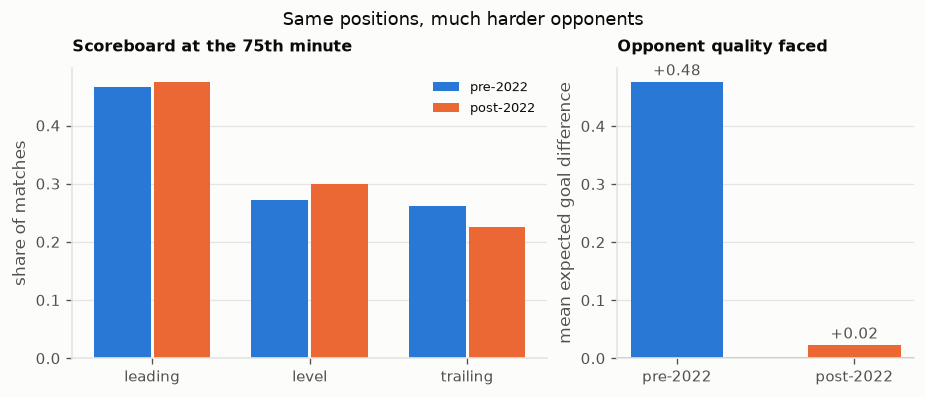

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.2),
                         gridspec_kw={"width_ratios": [1.6, 1]})
a = axes[0]
sh75 = (pd.crosstab(at75.era, at75.at75, normalize="index")
        .reindex(index=["pre", "post"])[["leading", "level", "trailing"]])
x = np.arange(3)
a.bar(x - 0.19, sh75.loc["pre"], width=0.36, color=viz.BLUE, label="pre-2022")
a.bar(x + 0.19, sh75.loc["post"], width=0.36, color=viz.ORANGE, label="post-2022")
a.set_xticks(x)
a.set_xticklabels(sh75.columns)
a.set_ylabel("share of matches")
a.set_title("Scoreboard at the 75th minute", fontsize=9.5)
a.legend(fontsize=8)
viz.despine(a)

b = axes[1]
opp = mt.groupby("era").expected_gd.mean().reindex(["pre", "post"])
b.bar([0, 1], opp.values, width=0.52, color=[viz.BLUE, viz.ORANGE])
for i, v in enumerate(opp.values):
    b.annotate(f"{v:+.2f}", (i, v), xytext=(0, 4), textcoords="offset points",
               ha="center", fontsize=9, color=viz.INK_2)
b.axhline(0, color=viz.INK_2, lw=1.0)
b.set_xticks([0, 1])
b.set_xticklabels(["pre-2022", "post-2022"])
b.set_ylabel("mean expected goal difference")
b.set_title("Opponent quality faced", fontsize=9.5)
viz.despine(b)

fig.suptitle("Same positions, much harder opponents", fontsize=11)
plt.show()

**This is the part that did not improve.**

The shortfall is **−0.50** pre and **−0.41** post, a change of **+0.09, 95%
[−0.36, +0.77]**. The raw conceding rate in that cell rises 3.04 → 7.32 per 90,
alarming until the interval: [−0.08, +11.59]. Ten goals in 123 minutes
distinguishes nothing.

**The scoreboard distribution barely moves either** — Jordan reaches the 75th
minute leading in **47%** of matches in both eras.

**That is the interesting part.** Over the same period the opposition got much
harder: mean expected goal difference **+0.48 → +0.02**, and among matches
reaching 75' level, **+0.50 → −0.41**. Holding the same positions against that
much better opposition *is* the improvement — notebook 01's headline in another
register. The conversion from them did not improve at all.

So this section contributes a negative, and a useful one: **none of the
improvement came from managing tight matches better.** What the failure *is*
cannot be settled here — that needs shot locations or possession, and neither
exists for these matches.

### What it isn't

Built, and returned nothing. Reported because a null with an interval is a
result, and because each one closes off an explanation that would otherwise stay
live.

In [43]:
ms["blk"] = ms.date.dt.year * 2 + (ms.date.dt.month > 6)
ms["margin"] = ms.gf - ms.ga     # before the blocks are cut, or the draws lack it
SB = {e: [d for _, d in ms[ms.era == e].groupby("blk")] for e in ("pre", "post")}

def sboot(fn, nb=1200):
    obs = fn(ms[ms.era == "post"]) - fn(ms[ms.era == "pre"])
    vals = []
    for _ in range(nb):
        s = {e: pd.concat([SB[e][i] for i in rng.integers(0, len(SB[e]), len(SB[e]))])
             for e in ("pre", "post")}
        v = fn(s["post"]) - fn(s["pre"])
        if np.isfinite(v):
            vals.append(v)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return obs, lo, hi

NULLS = [
    ("share of time leading", lambda d: (d.min_leading / d.match_end).mean()),
    ("share of time trailing", lambda d: (d.min_trailing / d.match_end).mean()),
    ("scores first", lambda d: d.first_goal.eq("for").mean()),
    ("trailed -> avoided defeat", lambda d: d.recovered.dropna().mean()),
    ("win by 3+", lambda d: (d.margin >= 3).mean()),
    ("lose by 3+", lambda d: (d.margin <= -3).mean()),
]
rows = []
for lab, fn in NULLS:
    o, lo, hi = sboot(fn)   # collected, not just printed -- the figure below uses it
    rows.append({"measure": lab, "diff": o, "lo": lo, "hi": hi,
                 "excludes_0": bool(lo > 0 or hi < 0)})
nulls = pd.DataFrame(rows)   # drawn two cells below

In [44]:
# Scoring rate per 90 minutes ACTUALLY SPENT in each state. Both numerator and
# denominator move when a match is resampled, so the rate is what is bootstrapped.
def rate(d, st, direction="gf"):
    m = d[f"min_{st}"].sum()
    return d[f"{direction}_{st}"].sum() / m * 90 if m > 0 else np.nan

srows = []
for st in ("leading", "level", "trailing"):
    o, lo, hi = sboot(lambda d, ss=st: rate(d, ss))
    a, b = rate(ms[ms.era == "pre"], st), rate(ms[ms.era == "post"], st)
    srows.append({"measure": f"scoring rate, {st}", "diff": o, "lo": lo,
                  "hi": hi, "pre": a, "post": b})

# The comparison of interest as a single quantity: does the team push when behind?
def ratio(d):
    lv = rate(d, "level")
    return rate(d, "trailing") / lv if lv > 0 else np.nan

o, lo, hi = sboot(ratio)
srows.append({"measure": "trailing / level ratio", "diff": o, "lo": lo, "hi": hi})
state_nulls = pd.DataFrame(srows)
N_TRAIL = int(ms.gf_trailing.sum())   # the whole basis of the trailing comparison

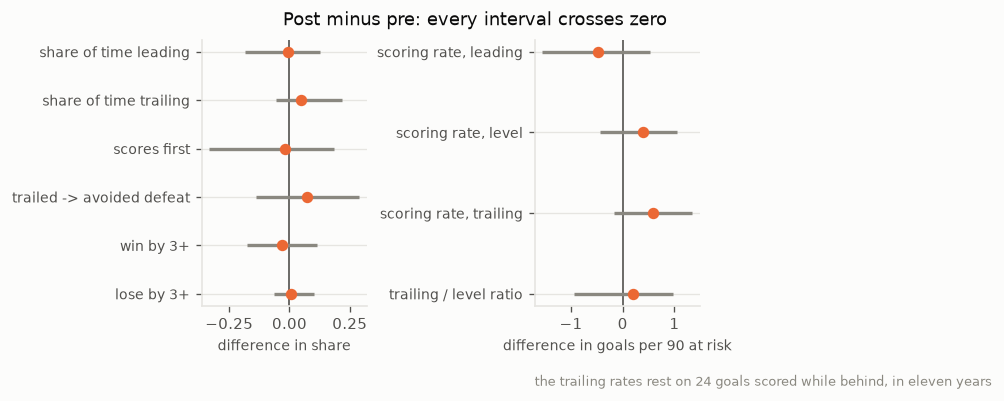

In [45]:
# Shares and goals-per-90 are not the same unit, so they do not share an axis.
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2))
for ax, tab, unit in ((axes[0], nulls, "difference in share"),
                      (axes[1], state_nulls, "difference in goals per 90 at risk")):
    d = tab.iloc[::-1].reset_index(drop=True)
    y = np.arange(len(d))
    ax.hlines(y, d.lo, d.hi, color=viz.INK_MUTED, lw=2.0)
    ax.scatter(d["diff"], y, color=viz.ORANGE, s=34, zorder=3)
    ax.axvline(0, color=viz.INK_2, lw=1.0, zorder=0)
    ax.set_yticks(y)
    ax.set_yticklabels(d.measure, fontsize=8.5)
    ax.set_xlabel(unit, fontsize=8.5)
    viz.despine(ax)
fig.suptitle("Post minus pre: every interval crosses zero", fontsize=11)
axes[1].annotate(f"the trailing rates rest on {N_TRAIL} goals scored while behind, "
                 f"in eleven years", xy=(0, -0.30), xycoords="axes fraction",
                 fontsize=8, color=viz.INK_MUTED)
plt.show()

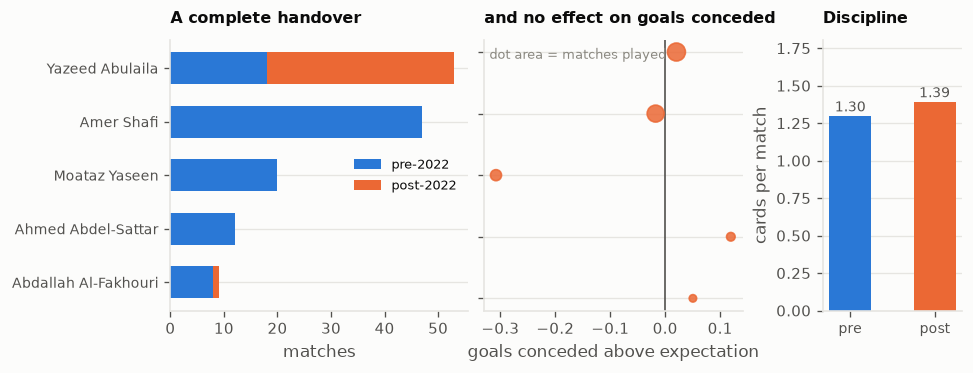

In [46]:
# The keeper: a complete handover, and no effect on goals conceded
kp = pd.read_csv(SQUAD / "keeper.csv")
kj = kp[kp.squad_id == "3e22f0fa"].merge(
    mt[["match_id", "era", "date", "ga", "expected_ga"]], on="match_id")
kj["above"] = kj.ga - kj.expected_ga
k = (kj.groupby("Player").agg(matches=("match_id", "size"),
                              pre=("era", lambda s: (s == "pre").sum()),
                              post=("era", lambda s: (s == "post").sum()),
                              first=("date", "min"), last=("date", "max"),
                              ga=("ga", "mean"), ga_above_expected=("above", "mean"))
     .sort_values("matches", ascending=False))
k["first"] = k["first"].dt.date
k["last"] = k["last"].dt.date
kk = k[k.matches >= 8].iloc[::-1]
fig, axes = plt.subplots(1, 3, figsize=(8.0, 3.0),
                         gridspec_kw={"width_ratios": [1.5, 1.3, 0.7]})
y = np.arange(len(kk))
a = axes[0]
a.barh(y, kk.pre, height=0.6, color=viz.BLUE, label="pre-2022")
a.barh(y, kk.post, left=kk.pre, height=0.6, color=viz.ORANGE, label="post-2022")
a.set_yticks(y)
a.set_yticklabels(kk.index, fontsize=8.5)
a.set_xlabel("matches")
a.set_title("A complete handover", fontsize=9.5)
a.legend(fontsize=8, loc="center right")
viz.despine(a)

b = axes[1]
# Area tracks matches played: a 20-match mean should not read as loudly as a
# 53-match one, and none of these carries an interval.
b.scatter(kk.ga_above_expected, y, color=viz.ORANGE, zorder=3,
          s=kk.matches.values * 2.2, alpha=0.85)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.set_yticks(y)
b.set_yticklabels([])
b.set_xlabel("goals conceded above expectation")
b.set_title("and no effect on goals conceded", fontsize=9.5)
b.annotate("dot area = matches played", xy=(0.02, 0.97), xycoords="axes fraction",
           va="top", fontsize=7.5, color=viz.INK_MUTED)
viz.despine(b)

c = axes[2]
cards = mt.groupby("era").n_cards.mean().reindex(["pre", "post"])
c.bar([0, 1], cards.values, width=0.5, color=[viz.BLUE, viz.ORANGE])
for i, v in enumerate(cards.values):
    c.annotate(f"{v:.2f}", (i, v), xytext=(0, 3), ha="center",
               textcoords="offset points", fontsize=8.5, color=viz.INK_2)
c.set_xticks([0, 1])
c.set_xticklabels(["pre", "post"], fontsize=8.5)
c.set_ylim(0, cards.max() * 1.3)
c.set_ylabel("cards per match")
c.set_title("Discipline", fontsize=9.5)
viz.despine(c)
plt.show()

- **Match state** — time leading, trailing, scoring first, recovering. Jordan did
  not become a team that manages the scoreboard differently.
- **Scoring rate by state.** The point estimates are seductive: pre-2022 Jordan
  looks like a front-runner, scoring *below its own level-state rate* when
  chasing — the opposite of Lago-Peñas & Gómez-López (2014). But it rests on **24
  goals scored while trailing in eleven years**, and the interval cannot carry it.
- **Margins** — heavy wins and defeats at the old rates. What changed is that
  matches got higher-scoring overall.
- **The goalkeeper.** The position does change hands — Shafi 47 matches and none
  after Feb 2021, Abulaila takes over — and goals conceded above expectation are
  identical. A plausible mechanism, measured and ruled out.
- **Discipline** — cards per match, unchanged.

Excluded rather than tested: **substitutions**, confounded by the 2020 five-sub
rule two years before the cut; **manager**, 15 spells and inseparable from squad
change at this n.

## Summary

| | | |
|---|---|---|
| **Supported** | a more settled team | minutes top-11 **+0.247** [+0.135, +0.351]; familiarity **+0.217** [+0.113, +0.337] |
| | the goals narrowed with it | outside the rarefied pre-2022 range — but **entirely explained** by the minutes, ratio to minutes-implied 2.14 → 2.13 |
| | more goals from midfield | **+0.148** [+0.039, +0.315] — but it cannot locate a date (section 0) |
| **Unchanged** | late conceding | a third of goals against in the last fifteen minutes, both eras |
| | level scorelines | shortfall −0.50 pre, −0.41 post; change **+0.09** [−0.36, +0.77] |
| **Not established** | dependence on one player | top-1 share sits *inside* the rarefied range |
| | game management, keeper, discipline, margins | every interval spans zero |

### So how did the results get better?

**Through the attack, from a narrower group, with a more settled team.** More of
the goals from a small set of players and from midfield, minutes concentrated in
fewer men, those men having played together more. Against opposition that got
substantially harder — expected goal difference **+0.48 → +0.02** — that produced
better results.

**Not through game management.** Same scoreboard positions at the 75th minute,
converted exactly as badly. Not through the goalkeeper or discipline either. The
list of things that *didn't* change is what stops "Jordan got better" from being
a story you can tell any way you like.

### What this licenses

A **coincidence with uncertainty**, and no more. Squad change, coaching change
and scheduling all move together across mid-2022, ~40 matches follow it, and no
design here separates them. The one thing worth adding beyond the association is
a caution: a rise carried by a narrow group is more fragile than one carried by a
broad one, and **top-3 share is the number to watch** if the level slips.

## What we can still improve

Ranked by how much each would change what is above. The first corrects a claim
already made; the rest are things this notebook does not know.

### 1. Section 5's shortfall is partly the model's fault

Its expectation comes from simulating the last fifteen minutes at each fixture's
own model goal rates — at a **constant rate whatever the scoreboard says**. The
match-status literature says that is wrong here specifically: late goals are more
common when a match is level, everywhere, for everyone. Two diagnostics on the
same 36 matches:

In [47]:
# Does the constant-rate model fit the last fifteen minutes of a level match?
late = pd.DataFrame([{"match_id": m,
                      "gf75": sum(1 for x, d in TL[m][0] if x > 75 and d > 0),
                      "ga75": sum(1 for x, d in TL[m][0] if x > 75 and d < 0)}
                     for m in L.match_id]).merge(L, on="match_id")
sg, sd = [], []
for r in late.itertuples():
    kf = rng.poisson(r.expected_gf * 15 / 90, 40000)
    ka = rng.poisson(r.expected_ga * 15 / 90, 40000)
    sg.append((kf + ka).mean())
    sd.append((kf == ka).mean())
# both halves of this comparison are drawn two cells below

In [48]:
# DIRECTION is the part no general effect explains. "Level matches produce more
# late goals" predicts volume. It does not predict them going one way.
f, g = int(late.gf75.sum()), int(late.ga75.sum())
sh = []
for _ in range(20000):
    d = late.sample(len(late), replace=True, random_state=int(rng.integers(1e9)))
    t = d.gf75.sum() + d.ga75.sum()
    if t:
        sh.append(d.gf75.sum() / t)
sh_lo, sh_hi = np.percentile(sh, [2.5, 97.5])
mdl = (late.expected_gf / (late.expected_gf + late.expected_ga)).mean()
# drawn by the next cell

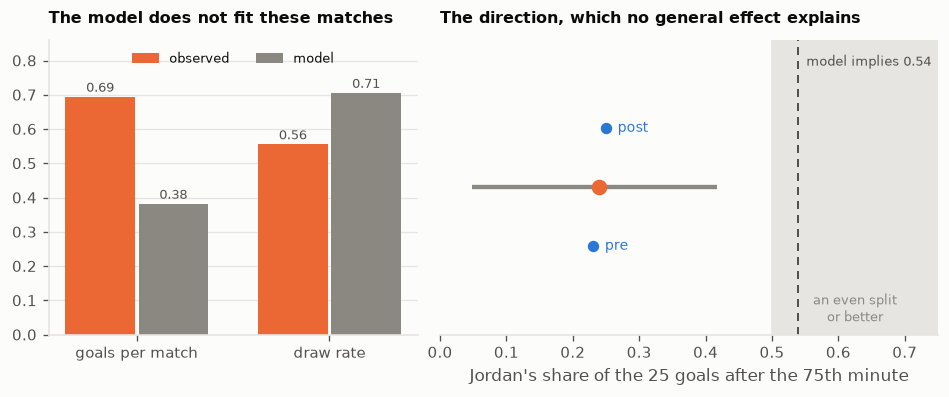

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2),
                         gridspec_kw={"width_ratios": [1, 1.35]})
a = axes[0]
x = np.arange(2)
obs_v = [(late.gf75 + late.ga75).mean(), (late.pts == 1).mean()]
mod_v = [np.mean(sg), np.mean(sd)]
for off, vals, col, lab in ((-0.19, obs_v, viz.ORANGE, "observed"),
                            (0.19, mod_v, viz.INK_MUTED, "model")):
    a.bar(x + off, vals, width=0.36, color=col, label=lab)
    for xi, v in zip(x + off, vals):
        a.annotate(f"{v:.2f}", (xi, v), xytext=(0, 3),
                   textcoords="offset points", ha="center", fontsize=8,
                   color=viz.INK_2)
a.set_xticks(x)
# two different units, side by side on purpose -- say so rather than hide it
a.set_xticklabels(["goals per match", "draw rate"])
a.set_ylim(0, max(obs_v + mod_v) * 1.22)
a.set_title("The model does not fit these matches", fontsize=9.5)
a.legend(fontsize=8, loc="upper center", ncol=2)
viz.despine(a)

b = axes[1]
b.axvspan(0.5, 0.75, color=viz.GRID, zorder=0)
b.annotate("an even split\nor better", xy=(0.625, 0.03),
           xycoords=("data", "axes fraction"), ha="center", va="bottom",
           fontsize=8, color=viz.INK_MUTED)
b.hlines(0, sh_lo, sh_hi, color=viz.INK_MUTED, lw=2.6)
b.scatter([f / (f + g)], [0], color=viz.ORANGE, s=70, zorder=4)
for k, (e, yy) in enumerate((("pre", -0.8), ("post", 0.8))):
    dd = late[late.era == e]
    b.scatter([dd.gf75.sum() / (dd.gf75.sum() + dd.ga75.sum())], [yy],
              color=viz.BLUE, s=34, zorder=4)
    b.annotate(e, (dd.gf75.sum() / (dd.gf75.sum() + dd.ga75.sum()), yy),
               xytext=(7, 0), textcoords="offset points", fontsize=8.5,
               color=viz.BLUE, va="center")
b.axvline(mdl, color=viz.INK_2, lw=1.2, ls=(0, (4, 3)))
b.annotate(f"model implies {mdl:.2f}", (mdl, 1.0),
           xycoords=("data", "axes fraction"), xytext=(5, -9),
           textcoords="offset points", fontsize=8, color=viz.INK_2, va="top")
b.set_ylim(-2, 2)
b.set_yticks([])
b.set_xlim(0, 0.75)
b.set_xlabel(f"Jordan's share of the {f + g} goals after the 75th minute")
b.set_title("The direction, which no general effect explains", fontsize=9.5)
viz.despine(b, keep=("bottom",))
plt.show()

**Re-centre section 5 on direction, not volume.** A busy last fifteen minutes in
a level match is ordinary football. Those goals going one way **three times in
four**, in fixtures the model makes Jordan the favourite in, is not — and it
holds in both eras. Keep the rate ratio and the points shortfall as symptoms
beneath it, never as clean comparisons.

### 2. There is no placebo here

The plan calls for the same pipeline on three or four comparable AFC nations;
notebook 01 does it for strength, this notebook does nothing. Every measure is
Jordan against its own past, so anything really about international football in
the 2020s — squads settling, scoring narrowing, late goals rising — would look
identical. **The largest hole**, and section 0 cannot fill it: that check moves
the date, not the team.

Cost: ~600 match reports, mostly uncached. A cheap partial version would take
only the level-at-75 finding, which needs goal minutes and nothing else.

### 3. Three planned squad measures were never built

XI age, debuts per window, squad turnover (Jaccard). The data is already on disk.
Debuts look like they would say something — **13 in 2021, then 1 and 1** — but
those years hold 21, 6 and 5 covered matches, so per match it is 0.62 → 0.17 →
0.20. Smaller than the counts suggest, and exactly why it needs building with an
interval rather than quoting.

### 4. The mechanism is out of reach, and will stay there

The obvious reading of section 5 — chasing a winner, caught on the break — needs
shot locations or possession. Possession exists for 27 matches, concentrated
after 2023, so filling it in would put the coverage boundary on the treatment
date. It stays a description, not an explanation.

### 5. Nineteen matches have no event feed

14 friendlies, 5 competitive: FBref reports with no timeline, so they reach the
squad measures but nothing in sections 4-6. Coverage is balanced across eras at
89%, so noise rather than bias — but it caps the post side near 40 matches, which
is why the state-crossed intervals are as wide as they are.

### 6. Smaller, recorded so they are not rediscovered

- **Minutes at risk stop at 90** while stoppage is always played. Section 5
  survives eight added minutes; the clock is still wrong.
- **Managers have no stable id** — name-keyed, and checked by hand.
- **Six Arab Cup names** are unconfirmed transliteration matches, deliberately
  unmerged. Confirming them adds ten matches.
- **Notebooks 01 and 02 predate the manager fix**; notebook 02's
  column-completeness figure is stale.

## Appendix — one measure this notebook deliberately does not use

`match_table` carries `gf_above_expected` — goals minus the model's expectation
for that fixture. Tempting as an outcome, and wrong for this question.

The model refits every six months on data *before* each match, so the residual
measures how far Jordan beat its **contemporaneous forecast**, not how much it
improved. Jordan's attack rising and its opponents strengthening cancel in the
expectation: expected goals-for is flat across the boundary while actual rises. A
team improving faster than a 730-day half-life can track shows a positive
residual for that reason alone.

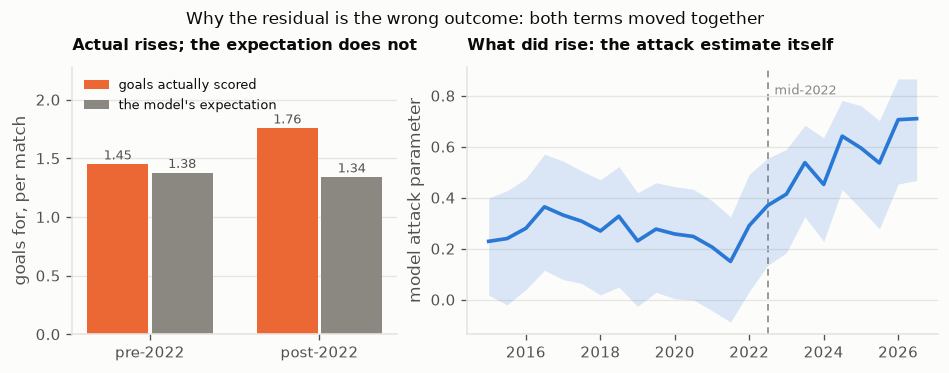

In [50]:
tr = pd.read_csv(ROOT / "outputs" / "jordan_strength_ci.csv", parse_dates=["date"])
g = mt.groupby("era")[["gf", "expected_gf"]].mean().reindex(["pre", "post"])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0),
                         gridspec_kw={"width_ratios": [1, 1.45]})
a = axes[0]
x = np.arange(2)
a.bar(x - 0.19, g.gf.values, width=0.36, color=viz.ORANGE, label="goals actually scored")
a.bar(x + 0.19, g.expected_gf.values, width=0.36, color=viz.INK_MUTED,
      label="the model's expectation")
for off, vals in ((-0.19, g.gf.values), (0.19, g.expected_gf.values)):
    for xi, v in zip(x + off, vals):
        a.annotate(f"{v:.2f}", (xi, v), xytext=(0, 3), ha="center",
                   textcoords="offset points", fontsize=8, color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(["pre-2022", "post-2022"])
a.set_ylim(0, max(g.gf.max(), g.expected_gf.max()) * 1.3)
a.set_ylabel("goals for, per match")
a.set_title("Actual rises; the expectation does not", fontsize=9.5)
a.legend(fontsize=7.5, loc="upper left")
viz.despine(a)

b = axes[1]
trw = tr[tr.date >= START]
b.fill_between(trw.date, trw.attack_lo, trw.attack_hi, color=viz.BLUE,
               alpha=0.16, lw=0)
b.plot(trw.date, trw.attack, color=viz.BLUE, lw=2.2)
viz.mark_split(b)
b.set_ylabel("model attack parameter")
b.set_title("What did rise: the attack estimate itself", fontsize=9.5)
viz.despine(b)
fig.suptitle("Why the residual is the wrong outcome: both terms moved together",
             fontsize=10)
plt.show()

Hence **shares and counts** throughout sections 1-3: they need no expectation, so
nothing there depends on the model being calibrated. Sections 4 and 5 do use it,
to adjust for opponent quality, and that is where its limits start to bite — the
first item in **What we can still improve**.